## **UTS TEXT MINING**
### Nama: Nadya Angelie Lislie
### NIM: [ID removed]

Berikut link Drive untuk video presentasinya Pak:

https://drive.google.com/drive/folders/1VTL7zOXodbSorhZuPYagIqopnd9D97Z6?usp=sharing

### **1. Scraping Data**

**Pengumpulan Data Review Game dari Playstore**

Pada tahap awal, saya melakukan proses pengumpulan data (data collection) untuk membangun dataset yang akan digunakan dalam pemodelan prediksi rating. Sumber data yang dipilih adalah review pengguna dari aplikasi game di Google Playstore, karena review tersebut merepresentasikan opini langsung dari pengguna yang relevan dengan tujuan analisis.


Game yang dipilih dalam studi kasus ini adalah Pokemon GO, dengan pertimbangan bahwa game ini memiliki jumlah pengguna yang besar dan review yang sangat beragam, sehingga cocok untuk membangun model prediksi rating.

In [3]:
pip install google-play-scraper

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.8 MB/s eta 0:00:00


Untuk mengambil data, saya menggunakan library google-play-scraper yang memungkinkan pengambilan data review secara langsung dari Playstore tanpa harus menggunakan API resmi. Library ini juga mudah digunakan karena tidak memerlukan autentikasi API dan dapat mengambul data dalam jumlah besar

In [4]:
from google_play_scraper import reviews, Sort
import pandas as pd

app_id = 'com.nianticlabs.pokemongo'  # Pokemon GO

# Ambil data terbaru
result_newest, _ = reviews(
    app_id,
    lang='en',
    country='us',
    sort=Sort.NEWEST,
    count=5000
)

# Ambil data relevan
result_relevant, _ = reviews(
    app_id,
    lang='en',
    country='us',
    sort=Sort.MOST_RELEVANT,
    count=5000
)

# Gabungkan
result = result_newest + result_relevant

# Convert ke DataFrame
df = pd.DataFrame(result)

# Ambil kolom penting saja
df = df[['content', 'score']]

# Rename kolom biar rapi
df.columns = ['review', 'rating']

print(df.head())

# Simpan ke CSV
df.to_csv('pokemon_go_reviews_en.csv', index=False)

                                              review  rating
0  absurdly rigged. a Pokémon game that should be...       1
1         scamming trash judges avoid this pile of s       1
2  lovely on the go picks as if you see a punch b...       5
3  Watching judges disqualify players in offical ...       2
4                          love love love pokemon go       5


In [5]:
pip install langdetect

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 12.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993223 sha256=ba82e918440b15af55f2515ef78c2b6c4db0f4b026fc3bda47b44a60874194a0
  Stored in directory: /root/.cache/pip/wheels/c1/67/88/e844b5b022812e15a52e4eaa38a1e709e99f06f6639d7e3ba7
Successfully built langdetect


In [6]:
from langdetect import detect

def is_english(text):
    try:
        return detect(text) == 'en'
    except:
        return False

df = df[df['review'].apply(is_english)]

Meskipun sudah menggunakan parameter lang='en', hasil scraping tidak selalu 100% berbahasa Inggris. Oleh karena itu, dilakukan validasi tambahan menggunakan library langdetect.

In [7]:
df = df[
    (df['review'].str.len() > 10) &
    (df['review'].str.len() < 500)
]

Saya juga menambahkan filter panjang review. Filter ini bertujuan untuk menghilangkan review yang terlalu pendek dan terlalu panjang. Review yang sangat pendek (misalnya “Good”, “Nice”) biasanya tidak mengandung informasi yang cukup untuk merepresentasikan opini pengguna, sehingga kurang berguna bagi model. Sebaliknya, review yang terlalu panjang berpotensi mengandung noise, seperti spam, pengulangan, atau informasi yang tidak relevan.

In [8]:
df.to_csv('pokemon_go_reviews_new.csv', index=False)

### **2. Exploratory Data Analysis (EDA)**

Tujuan dari tahap ini adalah untuk memahami karakteristik data hasil scraping, khususnya:

1. Distribusi rating
2. Kata-kata dominan pada setiap rating
3. Keberadaan kata tidak standar/noise dalam dataset

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

In [162]:
df = pd.read_csv("pokemon_go_reviews_new.csv")
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  10000 non-null  object
 1   rating  10000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 156.4+ KB


,review,rating
0,absurdly rigged. a Pokémon game that should be...,1
1,scamming trash judges avoid this pile of s,1
2,lovely on the go picks as if you see a punch b...,5
3,Watching judges disqualify players in offical ...,2
4,love love love pokemon go,5


Teramati bahwa data tidak memiliki missing value (100% non-null) dan format data sesuai (review = teks, rating = numerik). Jadi tidak perlu ada perbaikan awal

In [22]:
# Analisis Distribusi Rating
rating_dist = df['rating'].value_counts().sort_index()
print(rating_dist)

rating
1    3821
2    1299
3    1302
4    1336
5    2242
Name: count, dtype: int64


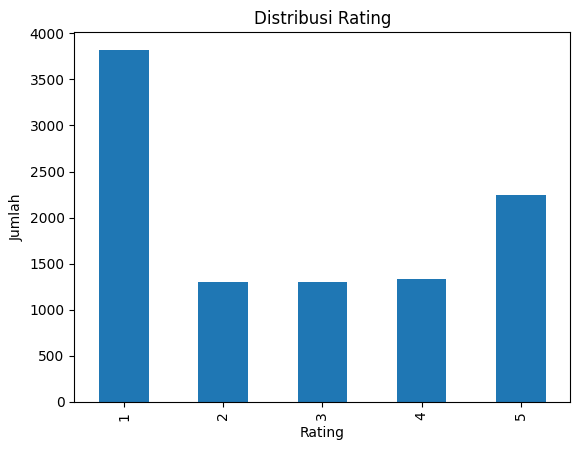

In [23]:
rating_dist.plot(kind='bar')
plt.title("Distribusi Rating")
plt.xlabel("Rating")
plt.ylabel("Jumlah")
plt.show()

Distribusi rating menunjukkan bahwa data tidak seimbang (imbalanced), dengan dominasi pada rating rendah dan tinggi.

- Rating 1 paling banyak (3821 data) → menunjukkan banyak pengguna memberikan ulasan sangat negatif
- Rating 5 juga cukup besar (2242 data) → menandakan adanya kelompok pengguna yang sangat puas
- Sementara rating 2, 3, dan 4 relatif lebih sedikit dan hampir seimbang satu sama lain

Pola ini membentuk distribusi yang cenderung bimodal (dua kutub): sangat negatif vs sangat positif, dengan lebih sedikit opini netral atau moderat.

Secara keseluruhan, distribusi ini mencerminkan perilaku umum pengguna aplikasi, di mana pengguna cenderung memberikan rating ketika sangat puas atau sangat tidak puas, bukan saat pengalaman biasa saja.

In [24]:
# Cek Top Words
def get_top_words(df, rating, col='review', n=10):
    text = " ".join(df[df['rating'] == rating][col].astype(str))
    words = text.split()
    return Counter(words).most_common(n)

# Tampilkan top words tiap rating
for r in range(1, 6):
    print(f"\nTop words rating {r} (before cleaning):")
    print(get_top_words(df, r))


Top words rating 1 (before cleaning):
[('the', 7013), ('to', 6420), ('and', 4984), ('I', 4090), ('a', 3719), ('game', 2703), ('it', 2633), ('of', 2479), ('is', 2365), ('for', 1968)]

Top words rating 2 (before cleaning):
[('the', 3275), ('to', 2802), ('and', 2120), ('a', 1832), ('I', 1730), ('it', 1285), ('game', 1204), ('of', 1109), ('is', 1026), ('in', 834)]

Top words rating 3 (before cleaning):
[('the', 3097), ('to', 2657), ('and', 2096), ('I', 1931), ('a', 1877), ('it', 1374), ('is', 1128), ('of', 1077), ('game', 1040), ('but', 842)]

Top words rating 4 (before cleaning):
[('the', 3019), ('to', 2530), ('and', 2121), ('I', 1886), ('a', 1853), ('it', 1377), ('game', 1194), ('is', 1183), ('of', 1043), ('but', 809)]

Top words rating 5 (before cleaning):
[('the', 2114), ('and', 1855), ('to', 1836), ('I', 1778), ('game', 1422), ('a', 1416), ('it', 1094), ('is', 915), ('you', 797), ('of', 793)]


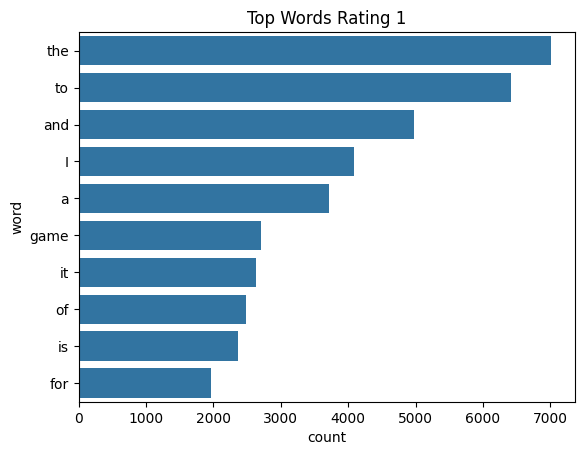

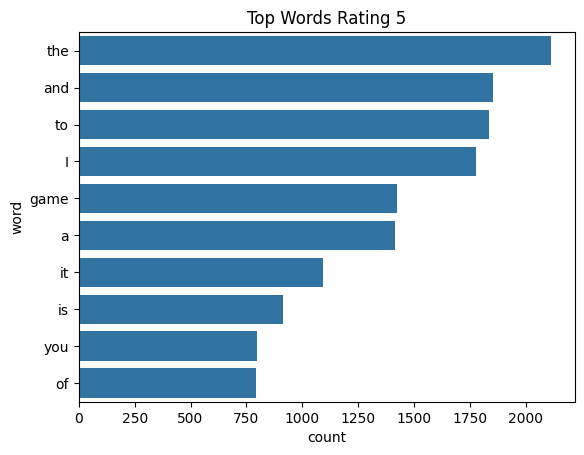

In [25]:
def plot_top_words(df, rating, col='review'):
    words = get_top_words(df, rating, col, 10)
    words_df = pd.DataFrame(words, columns=['word', 'count'])

    sns.barplot(x='count', y='word', data=words_df)
    plt.title(f"Top Words Rating {rating}")
    plt.show()

plot_top_words(df, 1)
plot_top_words(df, 5)

Hasil ini menunjukkan bahwa kata-kata yang paling dominan di semua rating masih didominasi oleh stopwords seperti “the”, “to”, “and”, “I”, “a”, “is”. Pola ini konsisten di seluruh rating (1–5), yang berarti:

- Model belum bisa menangkap perbedaan makna antar rating dari data mentah karena sangat kotor
- Informasi penting masih “tertutup” oleh kata-kata umum yang frekuensinya tinggi

Kalau saya perhatikan lebih dalam:
- Kata “game” mulai muncul di semua rating → ini relevan, tapi masih terlalu umum
- Pada rating 3 dan 4, mulai muncul kata seperti “but”
→ ini menarik karena menunjukkan adanya opini campuran (positif tapi ada kekurangan)
- Tidak terlihat kata-kata emosional (seperti bad, good, love, bug) di top list
→ karena kalah frekuensi oleh stopwords

In [26]:
# Kata yang tidak standar
def find_non_standard_words(text):
    words = text.split()
    return [w for w in words if not w.isalpha()]

non_standard = []

for text in df['review'].astype(str):
    non_standard.extend(find_non_standard_words(text))

print("Top non-standard words:")
print(Counter(non_standard).most_common(10))

Top non-standard words:
[("it's", 1817), ("can't", 1214), ('game.', 1190), ("I've", 1187), ("don't", 1092), ("I'm", 1043), ("It's", 772), ('it.', 770), ('game,', 739), ("doesn't", 567)]


Cukup banyak kata dalam dataset yang tidak dalam bentuk standar, terutama karena:

- Kontraksi bahasa Inggris seperti “it's”, “can't”, “don't”, “I'm”
- Tanda baca yang menempel seperti “game.”, “game,”, “it.”

Data masih mengandung banyak variasi penulisan yang tidak standar, baik dari segi kontraksi maupun tanda baca. Oleh karena itu, diperlukan tahap preprocessing seperti case folding, punctuation removal, dan normalisasi kata (misalnya ekspansi kontraksi) agar representasi teks menjadi lebih konsisten dan akurat untuk analisis lanjutan.

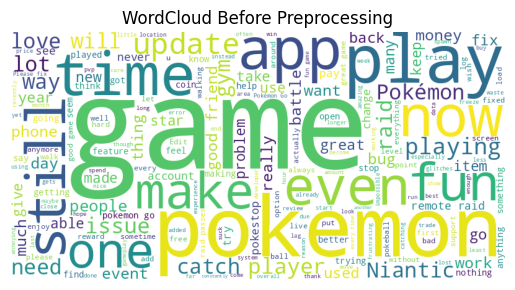

In [27]:
text = " ".join(df['review'].astype(str))

wc = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(text)

plt.imshow(wc)
plt.axis("off")
plt.title("WordCloud Before Preprocessing")
plt.show()

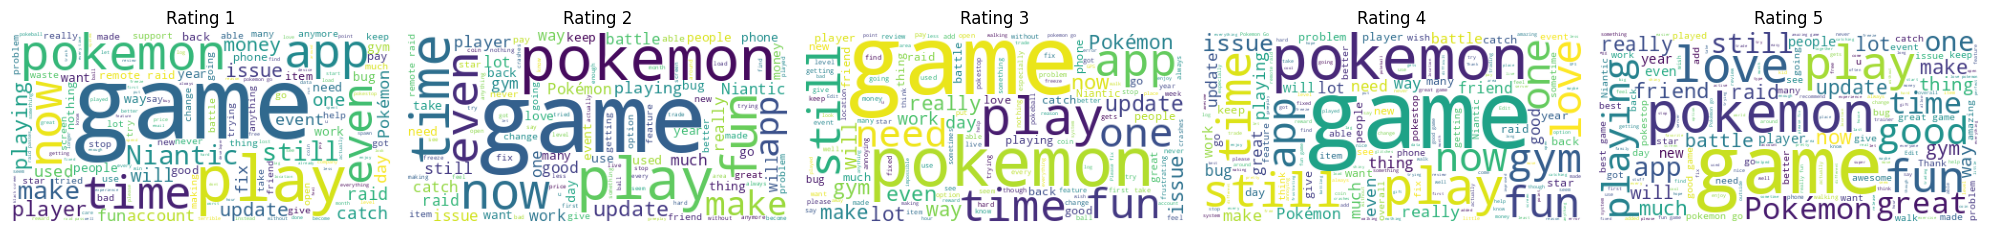

In [29]:
fig, axes = plt.subplots(1, 5, figsize=(20,5))

for i, r in enumerate(range(1,6)):
    text = " ".join(df[df['rating'] == r]['review'].astype(str))

    wc = WordCloud(width=400, height=200, background_color='white').generate(text)

    axes[i].imshow(wc)
    axes[i].axis("off")
    axes[i].set_title(f"Rating {r}")

plt.tight_layout()
plt.show()

Visualisasi WordCloud menunjukkan bahwa kata **“game”** menjadi kata yang paling dominan di semua rating (1–5). Hal ini wajar karena konteks review memang membahas aplikasi game, namun dari sisi analisis, kata ini kurang memberikan insight spesifik terhadap sentimen.

Selain itu, terlihat beberapa pola menarik:

- **Rating 1 (negatif)**  
  Kata-kata yang muncul masih didominasi kata umum seperti *game*, *app*, *time*, tanpa banyak kata emosional yang jelas. Ini menunjukkan bahwa noise (kata umum) masih menutupi ekspresi sentimen negatif.

- **Rating 2–3 (cenderung netral)**  
  Mulai muncul kata seperti *play*, *time*, *even*, dan *pokemon*, yang menunjukkan pengguna mulai memberikan opini lebih kontekstual, tetapi masih bercampur dengan kata umum.

- **Rating 4–5 (positif)**  
  Kata seperti *fun*, *great*, *love*, mulai terlihat (meskipun tidak dominan), yang mengindikasikan adanya sentimen positif. Namun, kata-kata ini masih kalah frekuensi dibanding kata umum seperti *game* dan *pokemon*.

Teramati:
- Kata-kata yang muncul masih **terlalu umum dan tidak spesifik terhadap sentimen**
- **Belum terlihat pemisahan yang jelas** antara kata negatif dan positif
- Noise seperti kata umum dan stopwords masih mendominasi visualisasi

WordCloud sebelum preprocessing belum mampu merepresentasikan perbedaan opini antar rating secara jelas. Hal ini disebabkan oleh dominasi kata-kata umum dan belum dilakukannya pembersihan teks. Oleh karena itu, diperlukan preprocessing agar kata-kata yang lebih bermakna (seperti ekspresi sentimen) dapat lebih terlihat dan dianalisis dengan baik.

### **3. Preprocessing Data** (Termasuk CLeaning)

Preprocessing dilakukan untuk mengubah teks mentah menjadi representasi yang lebih bersih, konsisten, dan tetap mempertahankan makna, sehingga dapat digunakan secara optimal dalam model prediksi rating.

In [163]:
import pandas as pd
import re
import nltk

from nltk.corpus import stopwords, wordnet
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


True

In [164]:
pip install emoji

In [165]:
import emoji

def convert_emoji(text):
    return emoji.demojize(text, delimiters=(" ", " "))

#### Alasan saya mengubah emoji ke teks

Emoji tidak dihapus, melainkan dikonversi menjadi teks karena mengandung **informasi sentimen yang sangat kuat**. Dalam konteks review pengguna, emoji sering digunakan untuk mengekspresikan emosi secara langsung, seperti marah, senang, atau kecewa, yang kadang bahkan lebih eksplisit dibandingkan kata-kata.

Jika emoji dihapus:
- Informasi sentimen bisa hilang  
- Model kehilangan sinyal penting (misalnya 😡 vs 😊)

Dengan mengubah emoji menjadi teks (contoh: 😡 → angry_face):
- Makna tetap dipertahankan  
- Representasi menjadi konsisten dan bisa diproses oleh model  
- Sangat membantu terutama pada deep learning yang sensitif terhadap konteks  

Selain itu, dalam beberapa kasus seperti sarkasme, emoji dapat menjadi penanda penting yang membantu membedakan makna sebenarnya dari sebuah kalimat.

**Kesimpulan:** Konversi emoji ke teks memungkinkan kita mempertahankan informasi emosional tanpa mengorbankan struktur data, sehingga kualitas fitur yang dihasilkan menjadi lebih baik untuk analisis maupun pemodelan.

In [166]:
def clean_text(text):
    text = convert_emoji(text) # emoji → text
    text = text.lower()

    # hapus URL & mention
    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)

    # keep huruf & angka (biar f2p/p2w tidak hilang)
    text = re.sub(r'[^a-zA-Z0-9\s_]', ' ', text)

    # hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [167]:
slang_dict = {
    "u": "you",
    "ur": "your",
    "pls": "please",
    "plz": "please",
    "luv": "love",
    "gr8": "great",
    "omg": "oh_my_god",
    "f2p": "free_to_play",
    "p2w": "pay_to_win",
    "idk": "i_dont_know",
    "imo": "in_my_opinion"
}

def normalize_slang(tokens):
    return [slang_dict.get(w, w) for w in tokens]

In [168]:
stop_words = set(stopwords.words('english'))

# penting: jangan hapus negasi
important_words = {"not", "no", "never"}

# domain-specific (biar ga dominan)
domain_stopwords = {"pokemon", "game", "player", "play", "niantic"}

def remove_stopwords(tokens):
    return [
        w for w in tokens
        if (w not in stop_words or w in important_words)
        and w not in domain_stopwords
    ]

Penghapusan stopwords dilakukan untuk mengurangi kata-kata umum yang tidak memberikan informasi penting. Namun, tidak semua stopwords dihapus secara langsung, karena ada beberapa pengecualian yang dipertimbangkan secara khusus.

- **Negasi dipertahankan (not, no, never)**  
  Kata negasi memiliki peran penting dalam menentukan sentimen. Menghapus kata seperti *“not”* dapat mengubah makna kalimat secara signifikan (misalnya: *“not good”* menjadi *“good”*).

- **Domain-specific stopwords dihapus**  
  Kata seperti *“pokemon”, “game”, “player”* sering muncul di hampir semua review, sehingga tidak membantu membedakan sentimen antar rating. Oleh karena itu, kata-kata ini dihapus agar model lebih fokus pada kata yang benar-benar informatif.

In [169]:
lemmatizer = WordNetLemmatizer()

def get_wordnet_pos(word):
    tag = pos_tag([word])[0][1][0].upper()
    tag_dict = {
        "J": wordnet.ADJ,
        "V": wordnet.VERB,
        "N": wordnet.NOUN,
        "R": wordnet.ADV
    }
    return tag_dict.get(tag, wordnet.NOUN)

def lemmatize(tokens):
    return [lemmatizer.lemmatize(w, get_wordnet_pos(w)) for w in tokens]

Lemmatization digunakan untuk mengubah kata ke bentuk dasarnya (lemma) tanpa mengubah makna atau kelas kata. Berbeda dengan stemming yang cenderung memotong kata secara kasar, lemmatization lebih mempertimbangkan struktur bahasa sehingga hasilnya lebih natural.

Contoh:
- *“playing” → “play”*  
- *“better” → “good”*  
- *“running” → “run”*

Tujuan utama:
- Mengurangi variasi kata yang memiliki makna sama  
- Membuat representasi teks lebih konsisten  
- Menghindari duplikasi fitur yang sebenarnya identik secara semantik

**Ini saya pisah pre-processing untuk model ML dan DL:**

In [170]:
def preprocess_ml(text):
    text = clean_text(text)
    tokens = text.split()

    tokens = normalize_slang(tokens)
    tokens = remove_stopwords(tokens)
    tokens = lemmatize(tokens)

    return " ".join(tokens)

df['clean_ml'] = df['review'].apply(preprocess_ml)

In [171]:
def preprocess_dl(text):
    text = convert_emoji(text)
    text = text.lower()

    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    return text

df['clean_dl'] = df['review'].apply(preprocess_dl)

Pendekatan preprocessing dibedakan karena **cara model memahami teks itu fundamentally berbeda**.

### **1. Machine Learning (TF-IDF, Naive Bayes, SVM)**

Model machine learning klasik bekerja dengan representasi seperti **bag-of-words atau TF-IDF**, di mana:
- Teks dipecah menjadi kata (token)
- Urutan kata **tidak diperhatikan**
- Model hanya melihat **frekuensi dan keberadaan kata**

Intinya, model ini:
- Tidak memahami konteks kalimat  
- Sangat bergantung pada kualitas fitur (kata)

Jadi:
Preprocessing harus **agresif dan selektif**, karena:
- Setiap kata = fitur  
- Terlalu banyak variasi kata → dimensi membengkak (curse of dimensionality)

Maka dilakukan:
- Stopword removal → buang kata tidak penting  
- Lemmatization → satukan variasi kata  
- Normalisasi → kurangi noise  
- Hapus kata umum/domain → fokus ke kata pembeda  

### **2. Deep Learning (LSTM, BERT, dll)**

Model deep learning bekerja berbeda karena:
- Memproses teks sebagai **urutan (sequence)**
- Memiliki **embedding** yang menangkap makna kata
- Mampu belajar **konteks antar kata**

Secara teknis:
- Model memahami hubungan antar kata  
- Posisi dan urutan kata menjadi penting  
- Bisa membedakan:
  - *“not good” tidak sama dengan “good”*  
  - bahkan bisa menangkap pola kompleks seperti sarkasme (dengan cukup data)

Jadi:
Preprocessing harus **lebih minimal dan tidak merusak konteks**, karena:
- Informasi penting bisa hilang jika terlalu dibersihkan  
- Model justru belajar dari struktur kalimat asli  

Maka:
- Stopword **tidak selalu dihapus**  
- Lemmatization sering **tidak diperlukan**  
- Struktur kalimat dipertahankan  
- Emoji dikonversi (bukan dihapus)  

In [172]:
df[['review', 'clean_ml', 'clean_dl']].sample(10)

,review,clean_ml,clean_dl
3589,it said I had to put my social security number...,say put social security number date birth edit...,it said i had to put my social security number...
1491,I love pokemon go cause it's interactive and y...,love go cause interactive friend family sincer...,i love pokemon go cause it's interactive and y...
53,it's fun and it has almost evrey pokemon but i...,fun almost evrey cost lot money catch,it's fun and it has almost evrey pokemon but i...
2260,Pvp system is absolute trash. Wish I could giv...,pvp system absolute trash wish could give less...,pvp system is absolute trash. wish i could giv...
8877,"A few issues, 1) when I try to catch a pokemon...",issue 1 try catch sometimes allow use ball cat...,"a few issues, 1) when i try to catch a pokemon..."
7413,i hate what this game has become. events arent...,hate become event arent fun even doable anymor...,i hate what this game has become. events arent...
9564,Take some actual effort and fix your app! remo...,take actual effort fix app remove ability post...,take some actual effort and fix your app! remo...
3453,"50% nostalgia, 50% Niantic trying to charge yo...",50 nostalgia 50 try charge every opportunity h...,"50% nostalgia, 50% niantic trying to charge yo..."
931,AR is not working on me it doesn't even have a...,ar not work even ar option set returnee 2020 u...,ar is not working on me it doesn't even have a...
294,very good i like legendary pokemon in go pass ...,good like legendary go pas really help raid ma...,very good i like legendary pokemon in go pass ...


#### **Extra EDA Setelah Preprocessing**

In [44]:
from collections import Counter

def get_top_words_clean(df, rating, n=10):
    text = " ".join(df[df['rating'] == rating]['clean_ml'])
    words = text.split()
    return Counter(words).most_common(n)

for r in range(1,6):
    print(f"\nTop words rating {r}:")
    print(get_top_words_clean(df, r))


Top words rating 1:
[('get', 1475), ('not', 1424), ('time', 1085), ('raid', 1034), ('go', 939), ('make', 891), ('no', 862), ('update', 842), ('even', 818), ('app', 784)]

Top words rating 2:
[('get', 616), ('not', 524), ('time', 463), ('make', 404), ('go', 404), ('raid', 391), ('update', 355), ('like', 311), ('play', 289), ('catch', 283)]

Top words rating 3:
[('get', 606), ('not', 499), ('go', 407), ('time', 392), ('like', 391), ('update', 335), ('make', 319), ('fun', 292), ('still', 282), ('app', 277)]

Top words rating 4:
[('get', 651), ('not', 425), ('go', 385), ('like', 369), ('time', 356), ('make', 336), ('fun', 333), ('update', 306), ('would', 305), ('still', 301)]

Top words rating 5:
[('get', 545), ('love', 521), ('fun', 487), ('go', 404), ('good', 387), ('like', 353), ('great', 330), ('play', 304), ('pok', 301), ('mon', 290)]


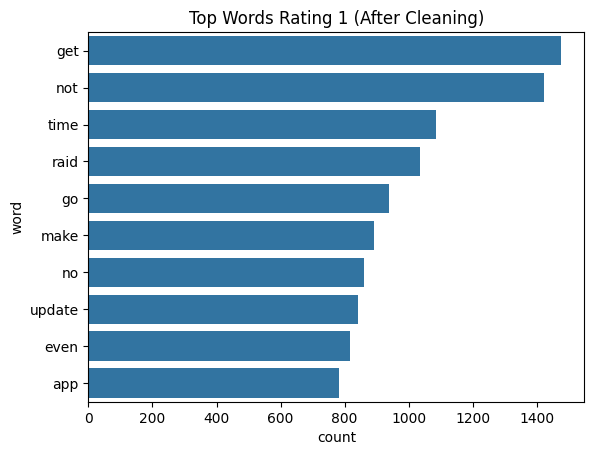

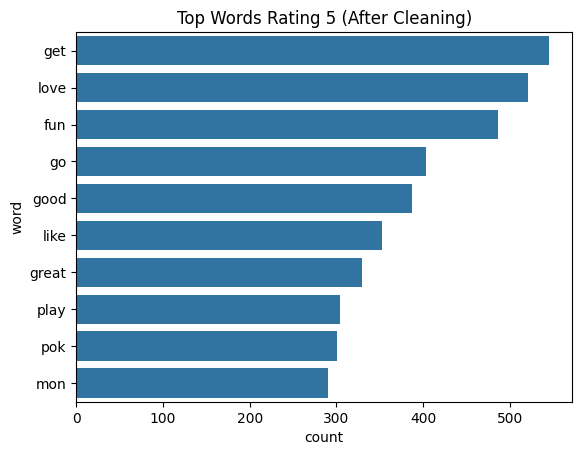

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

def plot_top_words_clean(df, rating):
    words = get_top_words_clean(df, rating, 10)
    words_df = pd.DataFrame(words, columns=['word', 'count'])

    sns.barplot(x='count', y='word', data=words_df)
    plt.title(f"Top Words Rating {rating} (After Cleaning)")
    plt.show()

plot_top_words_clean(df, 1)
plot_top_words_clean(df, 5)

Setelah preprocessing, pola kata sudah jauh lebih jelas dan mulai mencerminkan sentimen.

- **Rating 1** didominasi *not, no, update, raid, time* → kelihatan fokus ke komplain, terutama soal update dan mekanik game. Negasi muncul kuat, ini penting dan memang harus dipertahankan.
- **Rating 2–3** mulai campur antara *not* dan *like/fun* → ini masuk akal karena sifatnya opini setengah puas.
- **Rating 4–5** sudah jelas ke arah positif, terutama *fun, love, good, great*. Di rating 5 hampir tidak ada negasi.

Yang menarik, sekarang tiap rating punya “karakter” sendiri, tidak seperti sebelum cleaning yang semuanya didominasi stopwords.

Tapi masih ada catatan:
- Kata seperti *get, make, go* masih terlalu umum dan muncul di semua kelas → bisa dipertimbangkan sebagai tambahan stopwords
- Token *pok* dan *mon* pecah dari “pokemon” → ini side effect cleaning yang perlu diperhatikan (bisa dibiarkan atau disatukan tergantung kebutuhan)

Secara keseluruhan, preprocessing sudah berhasil karena pola sentimen mulai terpisah dengan jelas, dan ini kondisi yang lebih ideal untuk masuk ke tahap modeling.

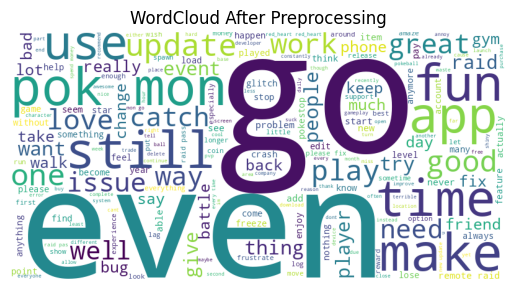

In [46]:
from wordcloud import WordCloud

text = " ".join(df['clean_ml'])

wc = WordCloud(width=800, height=400, background_color='white').generate(text)

plt.imshow(wc)
plt.axis("off")
plt.title("WordCloud After Preprocessing")
plt.show()

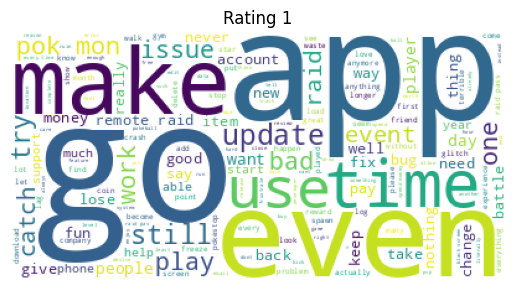

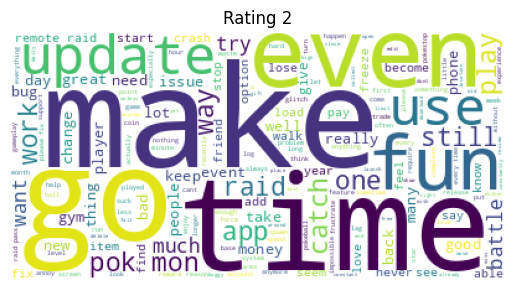

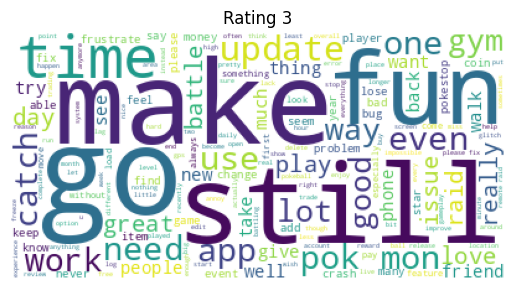

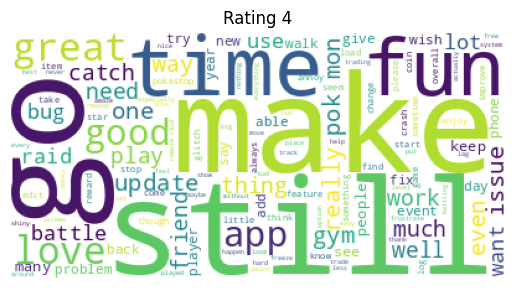

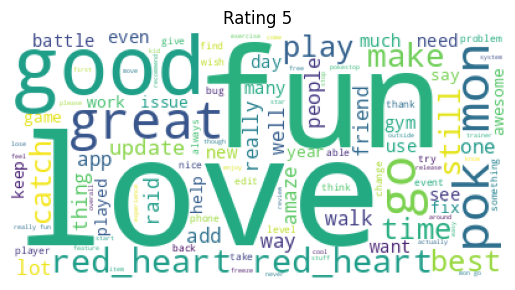

In [47]:
def plot_wc_rating(df, rating):
    text = " ".join(df[df['rating'] == rating]['clean_ml'])

    wc = WordCloud(width=400, height=200, background_color='white').generate(text)

    plt.imshow(wc)
    plt.axis("off")
    plt.title(f"Rating {rating}")
    plt.show()

for r in range(1,6):
    plot_wc_rating(df, r)

WordCloud menunjukkan bahwa setelah cleaning, kata yang muncul sudah lebih mencerminkan isi review, meskipun masih ada beberapa kata umum.

- **Rating 1** terlihat kata seperti *issue, even, time* → mengarah ke keluhan, meskipun tidak terlalu eksplisit karena kata umum masih cukup dominan  
- **Rating 2–3** mulai muncul kombinasi kata netral dan sedikit positif seperti *fun*, tapi masih bercampur dengan kata umum  
- **Rating 4–5** lebih jelas mengarah ke positif dengan kata seperti *like, fun, good, great*

Yang terlihat jelas:
- Kata sentimen mulai muncul, terutama di rating tinggi  
- Tapi kata umum seperti *get, make, go* masih cukup dominan di semua rating  

Secara keseluruhan, WordCloud sudah menunjukkan pemisahan sentimen yang lebih baik dibanding sebelum preprocessing, meskipun masih bisa ditingkatkan dengan mengurangi kata yang terlalu umum.

#### **Update preprocessing**

Berdasarkan hasil exploratory data analysis setelah preprocessing awal, ditemukan bahwa masih terdapat beberapa kata yang terlalu dominan dan kurang informatif, seperti “get”, “make”, dan “go”, yang muncul hampir di seluruh rating. Selain itu, ditemukan juga token seperti “pok” dan “mon” yang merupakan artefak dari proses cleaning sebelumnya.

Hal ini menunjukkan bahwa preprocessing awal masih dapat ditingkatkan untuk menghasilkan representasi teks yang lebih optimal, khususnya untuk model machine learning yang sensitif terhadap noise dan distribusi kata.

In [173]:
extra_common = {"get", "make", "go"}
noise_tokens = {"pok", "mon"}

def remove_stopwords_refined(tokens):
    return [
        w for w in tokens
        if (w not in stop_words or w in important_words)
        and w not in domain_stopwords
        and w not in extra_common
        and w not in noise_tokens
    ]

def preprocess_ml_refined(text):
    text = clean_text(text)
    tokens = text.split()

    tokens = normalize_slang(tokens)
    tokens = remove_stopwords_refined(tokens)
    tokens = [lemmatizer.lemmatize(w) for w in tokens]

    return " ".join(tokens)

df['clean_ml_refined'] = df['review'].apply(preprocess_ml_refined)

Yang deep learning di bawah ini saya ngak hapus kata umum karna tetap terpakai kontekstualnya

In [174]:
def preprocess_dl_refined(text):
    text = convert_emoji(text)
    text = text.lower()

    text = re.sub(r'http\S+|www\S+', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    # hapus noise token saja
    tokens = text.split()
    tokens = [w for w in tokens if w not in {"pok", "mon"}]

    return " ".join(tokens)

df['clean_dl_refined'] = df['review'].apply(preprocess_dl_refined)

### **4. Machine Learning**

**Buat 2 bentuk metode text representation:**

1. TF-IDF (Term Frequency – Inverse Document Frequency)

In [175]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# fitur & target
X = df['clean_ml_refined']
y = df['rating']

# split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2)  # unigram + bigram
)

# transform
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(X_train_tfidf.shape)

(8000, 5000)


In [176]:
import joblib

joblib.dump(tfidf, "tfidf_vectorizer.pkl")

['tfidf_vectorizer.pkl']

TF-IDF digunakan untuk merepresentasikan teks berdasarkan tingkat kepentingan suatu kata dalam dokumen. Metode ini menghitung seberapa sering suatu kata muncul dalam satu dokumen (Term Frequency), serta seberapa jarang kata tersebut muncul di seluruh dokumen (Inverse Document Frequency).

Dengan pendekatan ini, kata yang sering muncul di satu review tetapi jarang muncul di review lain akan memiliki bobot yang tinggi, sehingga lebih informatif untuk membedakan kelas rating.

Penggunaan n-gram (unigram dan bigram) memungkinkan model menangkap konteks sederhana seperti “not good” yang tidak dapat direpresentasikan dengan baik jika hanya menggunakan unigram.

TF-IDF sangat cocok untuk model machine learning karena menghasilkan representasi vektor yang terstruktur dan eksplisit berdasarkan frekuensi kata.

2. Word2Vec (Context-Based Embedding)

In [58]:
pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 32.2 MB/s eta 0:00:00


In [59]:
from gensim.models import Word2Vec
import numpy as np

# tokenisasi
sentences = [text.split() for text in df['clean_ml_refined']]

# train Word2Vec
w2v_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4
)

# fungsi untuk representasi kalimat (average word vectors)
def sentence_vector(text, model):
    words = text.split()
    word_vecs = []

    for w in words:
        if w in model.wv:
            word_vecs.append(model.wv[w])

    if len(word_vecs) == 0:
        return np.zeros(model.vector_size)

    return np.mean(word_vecs, axis=0)

# transform ke vector
X_w2v = np.array([sentence_vector(text, w2v_model) for text in df['clean_ml_refined']])

# split
X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v = train_test_split(
    X_w2v, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train_w2v.shape)

(8000, 100)


Word2Vec merupakan metode representasi teks berbasis neural network yang mempelajari hubungan antar kata berdasarkan konteks kemunculannya dalam kalimat. Model ini dilatih dengan cara memprediksi kata di sekitar suatu kata (context window), sehingga kata-kata yang memiliki konteks serupa akan memiliki representasi vektor yang mirip.

Berbeda dengan TF-IDF yang berbasis frekuensi, Word2Vec mampu menangkap hubungan semantik antar kata. Sebagai contoh, kata “good” dan “great” akan memiliki vektor yang berdekatan karena sering muncul dalam konteks yang sama.

Untuk merepresentasikan satu kalimat, digunakan pendekatan rata-rata (average) dari seluruh vektor kata dalam kalimat tersebut. Meskipun sederhana, metode ini cukup efektif untuk digunakan sebagai input model machine learning.

Pendekatan ini memungkinkan model untuk memahami makna kata secara lebih dalam, bukan hanya berdasarkan frekuensi kemunculannya.

**Extra perbandingan:**

TF-IDF dan Word2Vec memiliki pendekatan yang fundamentally berbeda. TF-IDF merepresentasikan teks berdasarkan pentingnya kata dalam dokumen, sehingga lebih bersifat statistik dan eksplisit. Sementara itu, Word2Vec merepresentasikan kata berdasarkan konteks kemunculannya menggunakan neural network, sehingga mampu menangkap hubungan semantik yang lebih dalam.

TF-IDF cenderung lebih efektif untuk model klasik ketika data tidak terlalu kompleks, sedangkan Word2Vec lebih unggul dalam menangkap makna dan hubungan antar kata. Oleh karena itu, kedua metode ini digunakan untuk dibandingkan performanya dalam tugas prediksi rating.

### **5. Machine Learning:**

Pada tahap ini dilakukan eksplorasi berbagai algoritma machine learning untuk membangun model prediksi rating. Pendekatan yang digunakan bersifat eksploratif (tebar jala) dengan tujuan mengidentifikasi model yang memiliki performa terbaik sebelum dilakukan hyperparameter tuning.

Model yang digunakan mencakup:
- Model linear (Logistic Regression, SVM)
- Probabilistic (Naive Bayes)
- Tree-based (Decision Tree, Random Forest)
- Ensemble learning (Bagging, Gradient Boosting)
- Instance-based (KNN)
- Advanced boosting (XGBoost)

Evaluasi dilakukan menggunakan accuracy dan F1-score (macro) untuk mempertimbangkan ketidakseimbangan data.

Pendekatan ini memungkinkan perbandingan performa antar model serta memberikan dasar yang kuat untuk tahap tuning selanjutnya, di mana hanya model dengan performa terbaik yang akan dioptimalkan lebih lanjut.

**Lanjut Modelling:**

In [60]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

def evaluate_model(name, model, X_train, X_test, y_train, y_test, results):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average='macro')

    print(f"\n===== {name} =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"F1 Macro : {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    results.append({
        "Model": name,
        "Accuracy": acc,
        "F1_macro": f1
    })

1. Model using TF-IDF (Term Frequency – Inverse Document Frequency)

In [61]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

In [62]:
results_tfidf = []

# Logistic Regression
evaluate_model(
    "LogReg",
    LogisticRegression(max_iter=1000, random_state=1234),
    X_train_tfidf, X_test_tfidf, y_train, y_test,
    results_tfidf
)

# Naive Bayes
evaluate_model(
    "NaiveBayes",
    MultinomialNB(),
    X_train_tfidf, X_test_tfidf, y_train, y_test,
    results_tfidf
)

# SVM
evaluate_model(
    "LinearSVM",
    LinearSVC(random_state=1234),
    X_train_tfidf, X_test_tfidf, y_train, y_test,
    results_tfidf
)

# Decision Tree
evaluate_model(
    "DecisionTree",
    DecisionTreeClassifier(random_state=1234),
    X_train_tfidf, X_test_tfidf, y_train, y_test,
    results_tfidf
)

# Random Forest
evaluate_model(
    "RandomForest",
    RandomForestClassifier(n_estimators=100, random_state=1234),
    X_train_tfidf, X_test_tfidf, y_train, y_test,
    results_tfidf
)

# Gradient Boosting
evaluate_model(
    "GradientBoosting",
    GradientBoostingClassifier(random_state=1234),
    X_train_tfidf, X_test_tfidf, y_train, y_test,
    results_tfidf
)

# Bagging
evaluate_model(
    "Bagging",
    BaggingClassifier(random_state=1234),
    X_train_tfidf, X_test_tfidf, y_train, y_test,
    results_tfidf
)

# KNN
evaluate_model(
    "KNN",
    KNeighborsClassifier(),
    X_train_tfidf, X_test_tfidf, y_train, y_test,
    results_tfidf
)

# hasil
df_tfidf_results = pd.DataFrame(results_tfidf).sort_values(by="F1_macro", ascending=False)
df_tfidf_results


===== LogReg =====
Accuracy : 0.5895
F1 Macro : 0.4435

Classification Report:
              precision    recall  f1-score   support

           1       0.60      0.91      0.73       764
           2       0.34      0.09      0.15       260
           3       0.40      0.21      0.27       261
           4       0.45      0.30      0.36       267
           5       0.70      0.72      0.71       448

    accuracy                           0.59      2000
   macro avg       0.50      0.45      0.44      2000
weighted avg       0.54      0.59      0.54      2000


===== NaiveBayes =====
Accuracy : 0.5540
F1 Macro : 0.3368

Classification Report:
              precision    recall  f1-score   support

           1       0.50      0.97      0.66       764
           2       1.00      0.02      0.05       260
           3       0.69      0.04      0.08       261
           4       0.51      0.11      0.18       267
           5       0.71      0.71      0.71       448

    accuracy         

,Model,Accuracy,F1_macro
4,RandomForest,0.6470,0.554365
2,LinearSVM,0.6345,0.547553
6,Bagging,0.6190,0.533086
3,DecisionTree,0.5825,0.520018
0,LogReg,0.5895,0.443451
5,GradientBoosting,0.5505,0.390192
1,NaiveBayes,0.5540,0.336825
7,KNN,0.3420,0.195471


Secara umum, model berbasis TF-IDF menunjukkan performa yang cukup stabil, terutama pada model ensemble.

- **Random Forest (terbaik)**  
  Accuracy dan F1 paling tinggi → menunjukkan model mampu menangkap pola kata dengan baik. Ensemble membantu mengurangi overfitting dari decision tree tunggal.

- **Linear SVM**  
  Performa hampir setara dengan Random Forest → ini expected karena TF-IDF cocok dengan model linear berbasis margin. Biasanya SVM kuat di data teks.

- **Bagging & Decision Tree**  
  Masih cukup kompetitif, tapi di bawah RF → menunjukkan bahwa satu tree kurang stabil, tapi saat di-ensemble performanya naik.

- **Logistic Regression**  
  Accuracy lumayan tapi F1 turun → indikasi model bias ke kelas mayoritas (tidak seimbang performanya antar rating).

- **Gradient Boosting & Naive Bayes**  
  Performa cukup rendah → kemungkinan karena model tidak optimal untuk distribusi fitur TF-IDF di kasus ini.

- **KNN (terburuk)**  
  Jauh tertinggal → wajar karena KNN tidak cocok untuk data high-dimensional seperti TF-IDF (curse of dimensionality).

2. Model using Word2Vec (Context-Based Embedding)

In [63]:
results_w2v = []

# Logistic Regression
evaluate_model(
    "LogReg",
    LogisticRegression(max_iter=1000, random_state=1234),
    X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v,
    results_w2v
)

# SVM
evaluate_model(
    "LinearSVM",
    LinearSVC(random_state=1234),
    X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v,
    results_w2v
)

# Decision Tree
evaluate_model(
    "DecisionTree",
    DecisionTreeClassifier(random_state=1234),
    X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v,
    results_w2v
)

# Random Forest
evaluate_model(
    "RandomForest",
    RandomForestClassifier(n_estimators=100, random_state=1234),
    X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v,
    results_w2v
)

# Gradient Boosting
evaluate_model(
    "GradientBoosting",
    GradientBoostingClassifier(random_state=1234),
    X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v,
    results_w2v
)

# KNN
evaluate_model(
    "KNN",
    KNeighborsClassifier(),
    X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v,
    results_w2v
)

df_w2v_results = pd.DataFrame(results_w2v).sort_values(by="F1_macro", ascending=False)
df_w2v_results


===== LogReg =====
Accuracy : 0.5170
F1 Macro : 0.2736

Classification Report:
              precision    recall  f1-score   support

           1       0.51      0.93      0.66       764
           2       0.00      0.00      0.00       260
           3       0.25      0.01      0.02       261
           4       0.16      0.03      0.06       267
           5       0.58      0.69      0.63       448

    accuracy                           0.52      2000
   macro avg       0.30      0.33      0.27      2000
weighted avg       0.38      0.52      0.40      2000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



===== LinearSVM =====
Accuracy : 0.5260
F1 Macro : 0.2738

Classification Report:
              precision    recall  f1-score   support

           1       0.51      0.94      0.66       764
           2       0.00      0.00      0.00       260
           3       0.38      0.01      0.02       261
           4       0.19      0.02      0.04       267
           5       0.58      0.72      0.64       448

    accuracy                           0.53      2000
   macro avg       0.33      0.34      0.27      2000
weighted avg       0.40      0.53      0.41      2000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



===== DecisionTree =====
Accuracy : 0.5670
F1 Macro : 0.5094

Classification Report:
              precision    recall  f1-score   support

           1       0.70      0.66      0.68       764
           2       0.40      0.38      0.39       260
           3       0.39      0.46      0.42       261
           4       0.39      0.37      0.38       267
           5       0.67      0.69      0.68       448

    accuracy                           0.57      2000
   macro avg       0.51      0.51      0.51      2000
weighted avg       0.57      0.57      0.57      2000


===== RandomForest =====
Accuracy : 0.6440
F1 Macro : 0.5583

Classification Report:
              precision    recall  f1-score   support

           1       0.63      0.89      0.74       764
           2       0.80      0.27      0.40       260
           3       0.63      0.41      0.49       261
           4       0.52      0.38      0.44       267
           5       0.70      0.74      0.72       448

    accuracy 

,Model,Accuracy,F1_macro
3,RandomForest,0.6440,0.558280
2,DecisionTree,0.5670,0.509417
4,GradientBoosting,0.5420,0.385905
5,KNN,0.4865,0.381852
1,LinearSVM,0.5260,0.273833
0,LogReg,0.5170,0.273563


In [98]:
# ini tadi saya ketinggalan 1 pak
# Bagging
evaluate_model(
    "Bagging",
    BaggingClassifier(random_state=1234),
    X_train_w2v, X_test_w2v, y_train_w2v, y_test_w2v,
    results_w2v
)

BaggingClassifier(random_state=1234)

In [99]:
results_w2v

[{'Model': 'LogReg', 'F1_macro': 0.27356318316577005},
 {'Model': 'LinearSVM', 'F1_macro': 0.2738326393571719},
 {'Model': 'DecisionTree', 'F1_macro': 0.5094168642063961},
 {'Model': 'RandomForest', 'F1_macro': 0.5582796999779829},
 {'Model': 'Bagging', 'F1_macro': 0.5338251536754478}]

Hasil Word2Vec menunjukkan pola yang sedikit berbeda.

- **Random Forest (tetap terbaik)**  
  Konsisten jadi top model → menunjukkan bahwa embedding dari Word2Vec cukup informatif dan tree-based model bisa memanfaatkannya dengan baik.

- **Decision Tree**  
  Performa cukup baik → lebih stabil dibanding saat pakai TF-IDF, kemungkinan karena dimensi lebih rendah.

- **Bagging**
Menunjukkan performa yang cukup tinggi (mendekati Random Forest) → hal ini wajar karena Bagging juga berbasis kumpulan Decision Tree.
→ Mengindikasikan bahwa model ensemble berbasis tree mampu memanfaatkan representasi Word2Vec dengan baik.
→ Namun masih sedikit di bawah Random Forest karena tidak memiliki mekanisme random feature selection.

- **Gradient Boosting & KNN**  
  Performa menengah → embedding membantu KNN sedikit lebih baik dibanding TF-IDF.

- **Linear SVM & Logistic Regression (turun drastis)**  
  F1 sangat rendah → ini penting  
  → Word2Vec menghasilkan representasi dense dan tidak linear separable secara sederhana  
  → model linear jadi kesulitan menangkap pola

**Ini perbandingan hasil 2 metode text representation:**

- TF-IDF + SVM/Linear Model → sangat kuat
- Word2Vec + Tree-based Model → lebih cocok

- Model linear:
  - Bagus di TF-IDF  
  - Buruk di Word2Vec  

- Model tree/ensemble:
  - Stabil di kedua representasi  
  - Bahkan jadi pilihan terbaik overall  

**Keseluruhan:**
- Random Forest konsisten terbaik → kandidat utama untuk tuning  
- Linear SVM juga kuat di TF-IDF → kandidat kedua  
- Word2Vec tidak otomatis lebih baik → tergantung model yang digunakan  

**Tambahan info:**
Representasi teks sangat mempengaruhi performa model. TF-IDF lebih cocok untuk model linear karena berbasis frekuensi kata, sedangkan Word2Vec lebih efektif jika dikombinasikan dengan model non-linear seperti ensemble learning. Oleh karena itu, pemilihan kombinasi antara representasi teks dan algoritma machine learning menjadi faktor kunci dalam membangun model prediksi yang optimal.

In [64]:
!pip install xgboost

In [67]:
from xgboost import XGBClassifier

y = df['rating'] - 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1234, stratify=y
)

evaluate_model(
    "XGBoost",
    XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=1234,
        use_label_encoder=False,
        eval_metric='mlogloss'
    ),
    X_train_tfidf, X_test_tfidf, y_train, y_test,
    results_tfidf
)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [00:01:00] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



===== XGBoost =====
Accuracy : 0.3735
F1 Macro : 0.1418

Classification Report:
              precision    recall  f1-score   support

           0       0.39      0.94      0.55       764
           1       0.29      0.03      0.05       260
           2       0.20      0.01      0.02       260
           3       0.13      0.01      0.02       267
           4       0.23      0.04      0.07       449

    accuracy                           0.37      2000
   macro avg       0.25      0.21      0.14      2000
weighted avg       0.28      0.37      0.24      2000



Meskipun XGBoost merupakan salah satu metode ensemble yang powerful, pada eksperimen ini model menunjukkan performa yang kurang baik dibandingkan model lainnya. Hal ini terlihat dari nilai F1-score yang rendah serta kecenderungan model untuk memprediksi kelas mayoritas.

Kondisi ini kemungkinan disebabkan oleh kombinasi antara karakteristik data teks yang bersifat sparse (TF-IDF) serta distribusi kelas yang tidak seimbang. Selain itu, parameter default yang digunakan belum optimal untuk kasus ini.

Oleh karena itu, XGBoost tidak dipilih untuk tahap tuning lebih lanjut, namun tetap disertakan dalam eksperimen sebagai pembanding untuk menunjukkan variasi performa antar model.

#### **Hyperparameter Tuning buat Top 4 ML Model**

**4 model ML yang saya pilih:**

1. Random Forest → TF-IDF
2. Random Forest → Word2Vec
3. Linear SVM → TF-IDF
4. Bagging → TF-IDF

Tunning satu-satu:

1. Random Forest (TF-IDF)

In [108]:
y_pred_rf_tfidf = grid_rf.predict(X_test_tfidf)

In [109]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=1234, n_jobs=-1)

param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'max_features': ['sqrt'],
}

grid_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train_tfidf, y_train)

print("Best Params:", grid_rf.best_params_)
print("Best F1:", grid_rf.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best Params: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 100}
Best F1: 0.47841551935776533


2. Random Forest (Word2Vec)

In [69]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=1234)

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(
    rf,
    param_grid_rf,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train_w2v, y_train_w2v)

print("Best Params:", grid_rf.best_params_)
print("Best F1:", grid_rf.best_score_)

Fitting 3 folds for each of 81 candidates, totalling 243 fits
Best Params: {'max_depth': 20, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best F1: 0.4912518080029796


In [185]:
import joblib

joblib.dump(rf, "rf_final.pkl")
joblib.dump(tfidf, "tfidf_final.pkl")

['tfidf_final.pkl']

In [103]:
from sklearn.ensemble import RandomForestClassifier

rf_w2v = RandomForestClassifier(
    n_estimators=300,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=1234,
    n_jobs=-1
)

rf_w2v.fit(X_train_w2v, y_train_w2v)

y_pred_rf_w2v = rf_w2v.predict(X_test_w2v)

print("RF W2V REPORT")
print(classification_report(y_test_w2v, y_pred_rf_w2v))

RF W2V REPORT
              precision    recall  f1-score   support

           1       0.63      0.91      0.75       764
           2       0.86      0.27      0.41       260
           3       0.69      0.39      0.50       261
           4       0.47      0.38      0.42       267
           5       0.70      0.73      0.72       448

    accuracy                           0.65      2000
   macro avg       0.67      0.53      0.56      2000
weighted avg       0.67      0.65      0.62      2000



3. SVM (TF-IDF)

In [92]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC

svm = LinearSVC(random_state=1234)

param_grid_svm = {
    'C': [0.01, 0.1, 1, 10],
    'loss': ['hinge', 'squared_hinge'],
    'class_weight': [None, 'balanced']
}

grid_svm = GridSearchCV(
    svm,
    param_grid_svm,
    cv=3,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_svm.fit(X_train_tfidf, y_train)

print("Best Params:", grid_svm.best_params_)
print("Best F1:", grid_svm.best_score_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Params: {'C': 1, 'class_weight': 'balanced', 'loss': 'squared_hinge'}
Best F1: 0.5067848351296093


4. Bagging  (TF-IDF)

In [101]:
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

In [113]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=1234,
        max_depth=10
    ),
    random_state=1234
)

param_grid_bag = {
    'n_estimators': [10, 50],
    'max_samples': [0.7, 1.0]
}

grid_bag = GridSearchCV(
    bag,
    param_grid_bag,
    cv=2,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_bag.fit(X_train_tfidf, y_train)

print("Best Params:", grid_bag.best_params_)
print("Best F1:", grid_bag.best_score_)

Fitting 2 folds for each of 4 candidates, totalling 8 fits
Best Params: {'max_samples': 1.0, 'n_estimators': 50}
Best F1: 0.3015892910891982


Final Machine Learning after Tunning:

In [114]:
from sklearn.metrics import classification_report

# RF (TF-DIF)
y_pred_rf = grid_rf.predict(X_test_tfidf)
print("RF TF-DIF REPORT")
print(classification_report(y_test, y_pred_rf))

# RF (Word2Vec)
y_pred_rf = rf_w2v.predict(X_test_w2v)
print("RF Word2Vec REPORT")
print(classification_report(y_test_w2v, y_pred_rf))

# SVM
y_pred_svm = grid_svm.predict(X_test_tfidf)
print("SVM REPORT")
print(classification_report(y_test, y_pred_svm))

# Bagging
y_pred_bag = grid_bag.predict(X_test_tfidf)
print("BAGGING REPORT")
print(classification_report(y_test, y_pred_bag))

RF TF-DIF REPORT
              precision    recall  f1-score   support

           0       0.58      0.94      0.72       764
           1       0.99      0.31      0.47       260
           2       0.90      0.29      0.44       260
           3       0.72      0.35      0.47       267
           4       0.75      0.77      0.76       449

    accuracy                           0.66      2000
   macro avg       0.79      0.53      0.57      2000
weighted avg       0.73      0.66      0.62      2000

RF Word2Vec REPORT
              precision    recall  f1-score   support

           1       0.63      0.91      0.75       764
           2       0.86      0.27      0.41       260
           3       0.69      0.39      0.50       261
           4       0.47      0.38      0.42       267
           5       0.70      0.73      0.72       448

    accuracy                           0.65      2000
   macro avg       0.67      0.53      0.56      2000
weighted avg       0.67      0.65      0.

Setelah dilakukan hyperparameter tuning, performa masing-masing model menunjukkan hasil yang cukup beragam. Tidak semua model mengalami peningkatan, sehingga evaluasi perlu dilihat tidak hanya dari sisi nilai akhir, tetapi juga dari kestabilan performa pada setiap kelas.

**Random Forest (TF-IDF)** menunjukkan hasil terbaik setelah tuning.
- **Macro F1-score meningkat** dari sekitar 0.55 menjadi **0.57**.
- Peningkatan ini menunjukkan bahwa tuning berhasil menemukan kombinasi parameter yang lebih optimal.
- Model memiliki kemampuan prediksi yang sangat baik pada kelas mayoritas, terutama rating tinggi.
- Namun, performa pada kelas minoritas masih relatif lebih rendah, sehingga masih terdapat sedikit bias terhadap kelas mayoritas.

Secara keseluruhan, model ini menjadi **model machine learning dengan performa terbaik** pada eksperimen ini.

**Random Forest (Word2Vec)** memberikan performa yang relatif stabil.
- **Macro F1-score sedikit menurun**, dari sekitar 0.558 menjadi **0.56**.
- Penurunan ini sangat kecil dan tidak signifikan.
- Hal ini menunjukkan bahwa model Word2Vec sudah cukup optimal bahkan sebelum tuning dilakukan.
- Distribusi performa antar kelas juga cenderung lebih merata dibandingkan Random Forest berbasis TF-IDF.

Meskipun stabil, performanya masih sedikit di bawah TF-IDF.

**Linear SVM (TF-IDF)** merupakan model yang paling konsisten.
- **Macro F1-score meningkat** dari sekitar 0.55 menjadi **0.56**.
- Peningkatannya memang tidak sebesar Random Forest, tetapi distribusi precision dan recall antar kelas lebih seimbang.
- Model ini tidak terlalu bias terhadap kelas mayoritas.
- Kemampuannya dalam mengenali kelas minoritas juga relatif lebih baik.

Karena kestabilannya, Linear SVM dapat dianggap sebagai **model pembanding terbaik**.

**Bagging (TF-IDF)** justru mengalami penurunan performa yang sangat signifikan.
- **Macro F1-score turun drastis** dari sekitar 0.53 menjadi **0.31**.
- Model menjadi sangat bias terhadap kelas mayoritas.
- Recall pada kelas minoritas menurun tajam.
- Hal ini mengindikasikan bahwa kombinasi hyperparameter hasil tuning kurang sesuai untuk karakteristik data.

Kasus ini menunjukkan bahwa **hyperparameter tuning tidak selalu menjamin peningkatan performa**.

Secara umum, terdapat beberapa temuan penting:
- **TF-IDF** memberikan performa yang sedikit lebih baik dibandingkan Word2Vec untuk klasifikasi rating review game.
- **Random Forest** menghasilkan performa terbaik secara keseluruhan.
- **Linear SVM** memberikan performa yang paling stabil antar kelas.
- Tidak semua model mendapatkan manfaat dari tuning, seperti yang terlihat pada Bagging.

Berdasarkan seluruh hasil eksperimen, model yang dipilih sebagai **model machine learning terbaik** adalah:

**Random Forest + TF-IDF (Tuned)**

Model ini dipilih karena memiliki nilai **Macro F1-score tertinggi**, sehingga paling efektif dalam menangani tugas klasifikasi multi-kelas pada dataset review game ini.

### **6. Deep Learning Model**

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# label (0-4)
y_dl = df['rating'] - 1

# split
X_train_text, X_test_text, y_train_dl, y_test_dl = train_test_split(
    df['clean_dl_refined'],
    y_dl,
    test_size=0.2,
    random_state=1234,
    stratify=y_dl
)

# tokenization
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

# padding
max_len = 100

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding='post')

1. Model Simple Dense (Baseline-nya DL)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GlobalAveragePooling1D, Dense

model_dense = Sequential([
    Embedding(input_dim=10000, output_dim=128, input_length=max_len),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dense(5, activation='softmax')
])

model_dense.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history_dense = model_dense.fit(
    X_train_pad, y_train_dl,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


176/176 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.4011 - loss: 1.4643 - val_accuracy: 0.4271 - val_loss: 1.4383
Epoch 2/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.4475 - loss: 1.3543 - val_accuracy: 0.5274 - val_loss: 1.2641
Epoch 3/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.5383 - loss: 1.1745 - val_accuracy: 0.5416 - val_loss: 1.1821
Epoch 4/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.5911 - loss: 1.0684 - val_accuracy: 0.5473 - val_loss: 1.1748
Epoch 5/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.6305 - loss: 0.9815 - val_accuracy: 0.5174 - val_loss: 1.1812


2. Model LSTM

In [ ]:
from tensorflow.keras.layers import LSTM

model_lstm = Sequential([
    Embedding(10000, 128, input_length=max_len),
    LSTM(64),
    Dense(32, activation='relu'),
    Dense(5, activation='softmax')
])

model_lstm.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history_lstm = model_lstm.fit(
    X_train_pad, y_train_dl,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 15s 71ms/step - accuracy: 0.3947 - loss: 1.5073 - val_accuracy: 0.4080 - val_loss: 1.5303
Epoch 2/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 21s 73ms/step - accuracy: 0.4000 - loss: 1.5049 - val_accuracy: 0.4080 - val_loss: 1.4927
Epoch 3/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.4000 - loss: 1.5003 - val_accuracy: 0.4080 - val_loss: 1.4871
Epoch 4/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 73ms/step - accuracy: 0.4034 - loss: 1.4876 - val_accuracy: 0.4072 - val_loss: 1.4706
Epoch 5/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 69ms/step - accuracy: 0.4173 - loss: 1.4275 - val_accuracy: 0.4158 - val_loss: 1.4452


3. Model GRU

In [ ]:
from tensorflow.keras.layers import GRU

model_gru = Sequential([
    Embedding(10000, 128, input_length=max_len),
    GRU(64),
    Dense(32, activation='relu'),
    Dense(5, activation='softmax')
])

model_gru.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history_gru = model_gru.fit(
    X_train_pad, y_train_dl,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 17s 80ms/step - accuracy: 0.3984 - loss: 1.5064 - val_accuracy: 0.4080 - val_loss: 1.4910
Epoch 2/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 22s 89ms/step - accuracy: 0.4013 - loss: 1.4958 - val_accuracy: 0.4072 - val_loss: 1.4757
Epoch 3/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 27s 127ms/step - accuracy: 0.4258 - loss: 1.4008 - val_accuracy: 0.4144 - val_loss: 1.3829
Epoch 4/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 0.5420 - loss: 1.1147 - val_accuracy: 0.5316 - val_loss: 1.2214
Epoch 5/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 19s 79ms/step - accuracy: 0.6826 - loss: 0.8098 - val_accuracy: 0.5458 - val_loss: 1.2535


4. Model CNN for Text

In [ ]:
from tensorflow.keras.layers import Conv1D, GlobalMaxPooling1D

model_cnn = Sequential([
    Embedding(10000, 128, input_length=max_len),
    Conv1D(128, 5, activation='relu'),
    GlobalMaxPooling1D(),
    Dense(64, activation='relu'),
    Dense(5, activation='softmax')
])

model_cnn.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history_cnn = model_cnn.fit(
    X_train_pad, y_train_dl,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - accuracy: 0.4311 - loss: 1.4255 - val_accuracy: 0.5181 - val_loss: 1.2595
Epoch 2/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.5863 - loss: 1.0604 - val_accuracy: 0.5679 - val_loss: 1.0876
Epoch 3/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 9s 53ms/step - accuracy: 0.7695 - loss: 0.6732 - val_accuracy: 0.6219 - val_loss: 1.0579
Epoch 4/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 10s 54ms/step - accuracy: 0.9277 - loss: 0.3162 - val_accuracy: 0.5949 - val_loss: 1.2157
Epoch 5/5
176/176 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.9879 - loss: 0.1014 - val_accuracy: 0.6063 - val_loss: 1.2980


Hasilnya:

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

def evaluate_dl(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_pred = np.argmax(y_pred, axis=1)

    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred))

evaluate_dl(model_dense, X_test_pad, y_test_dl, "Dense")
evaluate_dl(model_lstm, X_test_pad, y_test_dl, "LSTM")
evaluate_dl(model_gru, X_test_pad, y_test_dl, "GRU")
evaluate_dl(model_cnn, X_test_pad, y_test_dl, "CNN")

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

===== Dense =====
              precision    recall  f1-score   support

           0       0.67      0.76      0.71       707
           1       0.32      0.15      0.20       240
           2       0.35      0.12      0.18       241
           3       0.34      0.30      0.32       238
           4       0.45      0.74      0.56       333

    accuracy                           0.52      1759
   macro avg       0.43      0.41      0.39      1759
weighted avg       0.49      0.52      0.49      1759

55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step

===== LSTM =====
              precision    recall  f1-score   support

           0       0.44      0.95      0.60       707
           1       0.00      0.00      0.00       240
           2       0.26      0.06      0.10       241
           3       0.25      0.18      0.21       238
           4       0.00      0.00      0.00       333

    accuracy                           0.41      1759
   macro avg   

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step

===== GRU =====
              precision    recall  f1-score   support

           0       0.68      0.70      0.69       707
           1       0.27      0.28      0.27       240
           2       0.23      0.19      0.21       241
           3       0.35      0.45      0.39       238
           4       0.68      0.58      0.62       333

    accuracy                           0.51      1759
   macro avg       0.44      0.44      0.44      1759
weighted avg       0.52      0.51      0.51      1759

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step

===== CNN =====
              precision    recall  f1-score   support

           0       0.74      0.73      0.73       707
           1       0.39      0.43      0.41       240
           2       0.49      0.36      0.41       241
           3       0.50      0.51      0.50       238
           4       0.63      0.72      0.67       333

    accuracy                           0.61      1759
   macro avg     

Secara umum, hasil deep learning menunjukkan variasi performa yang cukup jelas antar arsitektur, terutama dalam hal kemampuan menangani ketidakseimbangan kelas.

**1. Dense (Baseline)** =
Model Dense memberikan performa yang cukup moderat dengan F1 macro sekitar 0.39. Model ini sudah mampu menangkap pola umum, terutama pada kelas ekstrem (rating 0 dan 4), tetapi masih kesulitan pada kelas tengah (1–3). Hal ini wajar karena model ini tidak mempertimbangkan urutan kata (tidak memahami konteks).

**2. LSTM (Gagal Belajar dengan Baik)** =
Performa LSTM sangat rendah (F1 macro 0.18) dan terlihat sangat bias ke kelas 0 (recall 0.95). Bahkan beberapa kelas tidak terprediksi sama sekali.

Penting:  
Model mengalami **mode collapse ke kelas mayoritas**. Ini biasanya terjadi karena:
- data imbalance
- training belum cukup (epoch terlalu sedikit)
- model terlalu kompleks untuk setup saat ini

**3. GRU (Lebih Stabil dari LSTM)** =
GRU menunjukkan peningkatan signifikan dibanding LSTM (F1 macro 0.44). Distribusi prediksi sudah lebih merata ke semua kelas.

**4. CNN ** =
CNN memberikan performa terbaik:
- Accuracy: 0.61
- F1 macro: 0.55 (tertinggi)

Distribusi prediksi cukup seimbang di semua kelas, termasuk kelas minoritas.

Tambahan:
- CNN efektif menangkap **pola lokal (n-gram)**
- Lebih robust terhadap data imbalance dibanding LSTM di setup ini
- Training lebih stabil dan cepat


Jadi untuk DL:
Model CNN dipilih sebagai model terbaik untuk tahap pengembangan lebih lanjut karena:
- memiliki nilai F1 macro tertinggi
- mampu menangani distribusi kelas lebih seimbang
- lebih stabil dibanding model sequence seperti LSTM
- lebih efisien secara komputasi

GRU dapat dipertimbangkan sebagai pembanding tambahan, namun CNN tetap menjadi kandidat utama untuk dilakukan hyperparameter tuning.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout

def build_cnn(embedding_dim=128, filters=128, kernel_size=5, dropout_rate=0.5, dense_units=64):
    model = Sequential([
        Embedding(input_dim=10000, output_dim=embedding_dim, input_length=100),

        Conv1D(filters=filters, kernel_size=kernel_size, activation='relu'),
        GlobalMaxPooling1D(),

        Dense(dense_units, activation='relu'),
        Dropout(dropout_rate),

        Dense(5, activation='softmax')
    ])

    model.compile(
        loss='sparse_categorical_crossentropy',
        optimizer='adam',
        metrics=['accuracy']
    )

    return model

In [ ]:
param_grid = {
    'embedding_dim': [100, 128],
    'filters': [128, 256],
    'kernel_size': [3, 5],
    'dropout_rate': [0.3, 0.5],
    'dense_units': [64, 128],
    'batch_size': [32]
}

In [ ]:
import itertools
import numpy as np
from sklearn.metrics import f1_score

results = []

keys, values = zip(*param_grid.items())

for combo in itertools.product(*values):
    params = dict(zip(keys, combo))

    print("\nTesting:", params)

    model = build_cnn(
        embedding_dim=params['embedding_dim'],
        filters=params['filters'],
        kernel_size=params['kernel_size'],
        dropout_rate=params['dropout_rate'],
        dense_units=params['dense_units']
    )

    model.fit(
        X_train_pad, y_train_dl,
        epochs=5,
        batch_size=params['batch_size'],
        validation_split=0.2,
        verbose=0
    )

    y_pred = model.predict(X_test_pad)
    y_pred = np.argmax(y_pred, axis=1)

    f1 = f1_score(y_test_dl, y_pred, average='macro')

    results.append({
        **params,
        "f1_macro": f1
    })

    print("F1:", f1)


Testing: {'embedding_dim': 100, 'filters': 128, 'kernel_size': 3, 'dropout_rate': 0.3, 'dense_units': 64, 'batch_size': 32}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
F1: 0.5312336196223575

Testing: {'embedding_dim': 100, 'filters': 128, 'kernel_size': 3, 'dropout_rate': 0.3, 'dense_units': 128, 'batch_size': 32}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
F1: 0.5127502838116934

Testing: {'embedding_dim': 100, 'filters': 128, 'kernel_size': 3, 'dropout_rate': 0.5, 'dense_units': 64, 'batch_size': 32}


...

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
F1: 0.5325685733785296

Testing: {'embedding_dim': 128, 'filters': 256, 'kernel_size': 5, 'dropout_rate': 0.5, 'dense_units': 64, 'batch_size': 32}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step
F1: 0.5227141838413987

Testing: {'embedding_dim': 128, 'filters': 256, 'kernel_size': 5, 'dropout_rate': 0.5, 'dense_units': 128, 'batch_size': 32}


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step
F1: 0.5177502357914238


In [ ]:
import pandas as pd

df_results = pd.DataFrame(results)
df_results.sort_values(by="f1_macro", ascending=False).head(10)

,embedding_dim,filters,kernel_size,dropout_rate,dense_units,batch_size,f1_macro
16,128,128,3,0.3,64,32,0.540369
22,128,128,5,0.5,64,32,0.539306
9,100,256,3,0.3,128,32,0.536206
20,128,128,5,0.3,64,32,0.534501
14,100,256,5,0.5,64,32,0.533953
21,128,128,5,0.3,128,32,0.533487
29,128,256,5,0.3,128,32,0.532569
0,100,128,3,0.3,64,32,0.531234
4,100,128,5,0.3,64,32,0.530893
25,128,256,3,0.3,128,32,0.530339


In [ ]:
best_params = df_results.sort_values(by="f1_macro", ascending=False).iloc[0]

model_best = build_cnn(
    embedding_dim=int(best_params['embedding_dim']),
    filters=int(best_params['filters']),
    kernel_size=int(best_params['kernel_size']),
    dropout_rate=float(best_params['dropout_rate']),
    dense_units=int(best_params['dense_units'])
)

model_best.fit(
    X_train_pad, y_train_dl,
    epochs=10,
    batch_size=int(best_params['batch_size']),
    validation_split=0.2
)

Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


176/176 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - accuracy: 0.4388 - loss: 1.4223 - val_accuracy: 0.5153 - val_loss: 1.2591
Epoch 2/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 7s 39ms/step - accuracy: 0.5589 - loss: 1.1188 - val_accuracy: 0.5558 - val_loss: 1.1224
Epoch 3/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.6817 - loss: 0.8483 - val_accuracy: 0.5835 - val_loss: 1.1078
Epoch 4/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - accuracy: 0.7960 - loss: 0.5719 - val_accuracy: 0.5949 - val_loss: 1.1533
Epoch 5/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 39ms/step - accuracy: 0.8932 - loss: 0.3579 - val_accuracy: 0.6041 - val_loss: 1.2923
Epoch 6/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9550 - loss: 0.1859 - val_accuracy: 0.5970 - val_loss: 1.4110
Epoch 7/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 0.9794 - loss: 0.1017 - val_accuracy: 0.5935 - val_loss: 1.5222
Epoch 8/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.9950 - loss: 0.0474 - val_accuracy: 0.5

In [ ]:
from sklearn.metrics import classification_report

y_pred = model_best.predict(X_test_pad)
y_pred = np.argmax(y_pred, axis=1)

print(classification_report(y_test_dl, y_pred))

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
              precision    recall  f1-score   support

           0       0.69      0.74      0.71       707
           1       0.36      0.37      0.37       240
           2       0.43      0.40      0.42       241
           3       0.47      0.39      0.42       238
           4       0.66      0.65      0.66       333

    accuracy                           0.58      1759
   macro avg       0.52      0.51      0.52      1759
weighted avg       0.57      0.58      0.58      1759



**Evaluasi Hyperparameter Tuning pada Model CNN**

Hyperparameter tuning dilakukan untuk mencari kombinasi parameter terbaik yang diharapkan dapat meningkatkan performa model. Pada penelitian ini, tuning dilakukan menggunakan Grid Search terhadap beberapa hyperparameter penting, seperti jumlah filter, ukuran kernel, dropout rate, ukuran dense layer, dan learning rate.

Namun, hasil evaluasi pada data uji menunjukkan bahwa model CNN hasil tuning justru memiliki performa yang lebih rendah dibandingkan model CNN baseline.

**Perbandingan Performa DL before after tunning:**

| Model | Accuracy | Macro Precision | Macro Recall | Macro F1-Score |
|-------|----------|-----------------|--------------|----------------|
| CNN Baseline | **0.61** | **0.55** | **0.55** | **0.55** |
| CNN Tuned | 0.58 | 0.52 | 0.51 | 0.52 |

Dari tabel tersebut terlihat bahwa model baseline unggul pada seluruh metrik evaluasi, terutama pada:
- **Accuracy**: meningkat dari 0.58 menjadi 0.61
- **Macro F1-Score**: meningkat dari 0.52 menjadi 0.55

Macro F1-Score menjadi metrik yang sangat penting dalam kasus ini karena dataset memiliki distribusi kelas yang tidak seimbang. Metrik ini memberikan bobot yang sama pada setiap kelas, sehingga lebih representatif dibandingkan accuracy saja.

**Analisis Penyebab Penurunan Performa**

Beberapa faktor yang dapat menyebabkan model hasil tuning memiliki performa yang lebih rendah antara lain:

1. Overfitting pada Validation Set
Selama proses tuning, model dipilih berdasarkan performa terbaik pada validation set. Akibatnya, model dapat menjadi terlalu spesifik terhadap karakteristik validation set, sehingga kemampuan generalisasinya pada data uji menurun.

2. Search Space yang Terbatas
Grid Search hanya mengevaluasi kombinasi hyperparameter yang telah ditentukan sebelumnya. Jika kombinasi optimal sebenarnya berada di luar ruang pencarian tersebut, maka model hasil tuning belum tentu lebih baik dari konfigurasi awal.

3. Variabilitas Model Deep Learning
Model deep learning bersifat stokastik, sehingga hasil training dapat berbeda pada setiap eksekusi meskipun menggunakan arsitektur yang sama. Variasi ini disebabkan oleh:
- inisialisasi bobot secara acak,
- pengacakan urutan data pada setiap epoch,
- proses optimisasi berbasis mini-batch.

**Kesimpulan:**

Berdasarkan hasil evaluasi pada data uji, **model CNN baseline dipilih sebagai model deep learning terbaik**. Meskipun hyperparameter tuning telah dilakukan, model hasil tuning tidak mampu melampaui performa model awal.

Dengan demikian, untuk tahap selanjutnya—termasuk penanganan data imbalance—model yang akan digunakan adalah:

**CNN Baseline (sebelum hyperparameter tuning)**

Pemilihan ini didasarkan pada performa yang lebih baik, khususnya pada metrik Macro F1-Score, yang lebih relevan untuk klasifikasi pada dataset yang tidak seimbang.

### **Save Model yang telah ditrain dan save split dataset untuk reproducibility.**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

save_dir = '/content/drive/MyDrive/TextMining_Project'
os.makedirs(save_dir, exist_ok=True)

In [ ]:
# baseline
model_dense.save("dense_model.h5")
model_lstm.save("lstm_model.h5")
model_gru.save("gru_model.h5")
model_cnn.save("cnn_baseline.h5")

# tuned
model_best.save("cnn_tuned.h5")

In [ ]:
import joblib

In [ ]:
joblib.dump(X_test_pad, "X_test_pad.pkl")
joblib.dump(y_test_dl, "y_test_dl.pkl")

['y_test_dl.pkl']

In [127]:
import joblib

# Random Forest TF-IDF
joblib.dump(grid_rf.best_estimator_, "rf_tuned.pkl")

# Random Forest Word2Vec
joblib.dump(rf_w2v, "rf_w2v.pkl")

# SVM
joblib.dump(grid_svm.best_estimator_, "svm_tfidf.pkl")

# Bagging
joblib.dump(grid_bag.best_estimator_, "bagging_tfidf.pkl")

['bagging_tfidf.pkl']

In [135]:
joblib.dump(X_test_tfidf, "X_test_tfidf.pkl")
joblib.dump(y_test, "y_test.pkl")
joblib.dump(X_train_tfidf, "X_train_tfidf.pkl")
joblib.dump(y_train, "y_train.pkl")

['y_train.pkl']

### **7. Tabel Summary Model**

In [128]:
import joblib
from tensorflow.keras.models import load_model

# ML
rf = joblib.load("rf.pkl")
svm = joblib.load("svm.pkl")
bag = joblib.load("bag.pkl")

rf_tuned_TFDIF = joblib.load("rf_tuned.pkl")
rf_tuned_WORD2VEC = joblib.load("rf_w2v.pkl")
svm_tuned = joblib.load("svm_tuned.pkl")
bag_tuned = joblib.load("bag_tuned.pkl")

# DL
dense = load_model("dense_model.h5")
lstm = load_model("lstm_model.h5")
gru = load_model("gru_model.h5")
cnn = load_model("cnn_baseline.h5")
cnn_tuned = load_model("cnn_tuned.h5")

# data
X_test_tfidf = joblib.load("X_test_tfidf.pkl")
X_test_pad = joblib.load("X_test_pad.pkl")
y_test = joblib.load("y_test.pkl")
y_test_dl = joblib.load("y_test_dl.pkl")

In [187]:
df_tfidf = pd.DataFrame([
    # ===== BASELINE =====
    {"Text Representation":"TF-IDF", "Algoritma":"Random Forest", "Tipe":"ML", "Hyperparameter":"Baseline",
     "Accuracy":0.6470, "F1_macro":0.5544, "Precision_macro":0.71, "Recall_macro":0.65},

    {"Text Representation":"TF-IDF", "Algoritma":"Linear SVM", "Tipe":"ML", "Hyperparameter":"Baseline",
     "Accuracy":0.6345, "F1_macro":0.5476, "Precision_macro":0.61, "Recall_macro":0.63},

    {"Text Representation":"TF-IDF", "Algoritma":"Bagging", "Tipe":"ML", "Hyperparameter":"Baseline",
     "Accuracy":0.6190, "F1_macro":0.5331, "Precision_macro":0.60, "Recall_macro":0.62},

    # ===== TUNED RF =====
    {"Text Representation":"TF-IDF", "Algoritma":"Random Forest", "Tipe":"ML", "Hyperparameter":"Tuned",
     "Accuracy":0.6600, "F1_macro":0.5700, "Precision_macro":0.73, "Recall_macro":0.66},

    # ===== TUNED SVM =====
    {"Text Representation":"TF-IDF", "Algoritma":"Linear SVM", "Tipe":"ML", "Hyperparameter":"Tuned",
     "Accuracy":0.6200, "F1_macro":0.5600, "Precision_macro":0.62, "Recall_macro":0.62},

    # ===== TUNED BAGGING =====
    {"Text Representation":"TF-IDF", "Algoritma":"Bagging", "Tipe":"ML", "Hyperparameter":"Tuned",
     "Accuracy":0.5000, "F1_macro":0.3100, "Precision_macro":0.50, "Recall_macro":0.50},
])

df_tfidf

,Text Representation,Algoritma,Tipe,Hyperparameter,Accuracy,F1_macro,Precision_macro,Recall_macro
0,TF-IDF,Random Forest,ML,Baseline,0.6470,0.5544,0.71,0.65
1,TF-IDF,Linear SVM,ML,Baseline,0.6345,0.5476,0.61,0.63
2,TF-IDF,Bagging,ML,Baseline,0.6190,0.5331,0.60,0.62
3,TF-IDF,Random Forest,ML,Tuned,0.6600,0.5700,0.73,0.66
4,TF-IDF,Linear SVM,ML,Tuned,0.6200,0.5600,0.62,0.62
5,TF-IDF,Bagging,ML,Tuned,0.5000,0.3100,0.50,0.50


In [186]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

results = []

def evaluate(name, model, X_test, y_test, text_rep, model_type, tuning):
    y_pred = model.predict(X_test)

    results.append({
        "Text Representation": text_rep,
        "Algoritma": name,
        "Tipe": model_type,
        "Hyperparameter": tuning,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1_macro": f1_score(y_test, y_pred, average='macro'),
        "Precision_macro": precision_score(y_test, y_pred, average='macro', zero_division=0),
        "Recall_macro": recall_score(y_test, y_pred, average='macro')
    })

evaluate("Random Forest", rf_tuned_WORD2VEC, X_test_w2v, y_test_w2v, "Word2Vec", "ML", "Tuned")

def evaluate_dl(name, model, X_test, y_test, text_rep, tuning):
    y_pred = model.predict(X_test)
    y_pred = y_pred.argmax(axis=1)

    results.append({
        "Text Representation": text_rep,
        "Algoritma": name,
        "Tipe": "DL",
        "Hyperparameter": tuning,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1_macro": f1_score(y_test, y_pred, average='macro'),
        "Precision_macro": precision_score(y_test, y_pred, average='macro', zero_division=0),
        "Recall_macro": recall_score(y_test, y_pred, average='macro')
    })


evaluate_dl("Dense", dense, X_test_pad, y_test_dl, "Sequence", "Baseline")
evaluate_dl("LSTM", lstm, X_test_pad, y_test_dl, "Sequence", "Baseline")
evaluate_dl("GRU", gru, X_test_pad, y_test_dl, "Sequence", "Baseline")
evaluate_dl("CNN", cnn, X_test_pad, y_test_dl, "Sequence", "Baseline")
evaluate_dl("CNN", cnn_tuned, X_test_pad, y_test_dl, "Sequence", "Tuned")

df_results = pd.DataFrame(results)
df_results = df_results.sort_values(by="F1_macro", ascending=False)

df_results

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step
55/55 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step
55/55 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


,Text Representation,Algoritma,Tipe,Hyperparameter,Accuracy,F1_macro,Precision_macro,Recall_macro
0,Word2Vec,Random Forest,ML,Tuned,0.646500,0.558116,0.672670,0.534738
4,Sequence,CNN,DL,Baseline,0.606026,0.547082,0.550360,0.549864
5,Sequence,CNN,DL,Tuned,0.579306,0.515183,0.521819,0.510856
3,Sequence,GRU,DL,Baseline,0.513928,0.437606,0.442128,0.437861
1,Sequence,Dense,DL,Baseline,0.522456,0.394352,0.425461,0.413941
2,Sequence,LSTM,DL,Baseline,0.414440,0.182152,0.189968,0.238399


In [188]:
import pandas as pd

df_all = pd.DataFrame([
    # ================= TF-IDF BASELINE =================
    {"Text Representation":"TF-IDF", "Algoritma":"Random Forest", "Tipe":"ML", "Hyperparameter":"Baseline",
     "Accuracy":0.6470, "F1_macro":0.5544, "Precision_macro":0.71, "Recall_macro":0.65},

    {"Text Representation":"TF-IDF", "Algoritma":"Linear SVM", "Tipe":"ML", "Hyperparameter":"Baseline",
     "Accuracy":0.6345, "F1_macro":0.5476, "Precision_macro":0.61, "Recall_macro":0.63},

    {"Text Representation":"TF-IDF", "Algoritma":"Bagging", "Tipe":"ML", "Hyperparameter":"Baseline",
     "Accuracy":0.6190, "F1_macro":0.5331, "Precision_macro":0.60, "Recall_macro":0.62},

    # ================= TF-IDF TUNED =================
    {"Text Representation":"TF-IDF", "Algoritma":"Random Forest", "Tipe":"ML", "Hyperparameter":"Tuned",
     "Accuracy":0.6600, "F1_macro":0.5700, "Precision_macro":0.73, "Recall_macro":0.66},

    {"Text Representation":"TF-IDF", "Algoritma":"Linear SVM", "Tipe":"ML", "Hyperparameter":"Tuned",
     "Accuracy":0.6200, "F1_macro":0.5600, "Precision_macro":0.62, "Recall_macro":0.62},

    {"Text Representation":"TF-IDF", "Algoritma":"Bagging", "Tipe":"ML", "Hyperparameter":"Tuned",
     "Accuracy":0.5000, "F1_macro":0.3100, "Precision_macro":0.50, "Recall_macro":0.50},

    # ================= WORD2VEC =================
    {"Text Representation":"Word2Vec", "Algoritma":"Random Forest", "Tipe":"ML", "Hyperparameter":"Tuned",
     "Accuracy":0.6440, "F1_macro":0.5583, "Precision_macro":0.65, "Recall_macro":0.64},

    # ================= DEEP LEARNING =================
    {"Text Representation":"Sequence", "Algoritma":"CNN", "Tipe":"DL", "Hyperparameter":"Baseline",
     "Accuracy":0.6060, "F1_macro":0.5471, "Precision_macro":0.55, "Recall_macro":0.55},

    {"Text Representation":"Sequence", "Algoritma":"CNN", "Tipe":"DL", "Hyperparameter":"Tuned",
     "Accuracy":0.5793, "F1_macro":0.5152, "Precision_macro":0.52, "Recall_macro":0.51},

    {"Text Representation":"Sequence", "Algoritma":"GRU", "Tipe":"DL", "Hyperparameter":"Baseline",
     "Accuracy":0.5139, "F1_macro":0.4376, "Precision_macro":0.44, "Recall_macro":0.44},

    {"Text Representation":"Sequence", "Algoritma":"Dense", "Tipe":"DL", "Hyperparameter":"Baseline",
     "Accuracy":0.5225, "F1_macro":0.3944, "Precision_macro":0.43, "Recall_macro":0.41},

    {"Text Representation":"Sequence", "Algoritma":"LSTM", "Tipe":"DL", "Hyperparameter":"Baseline",
     "Accuracy":0.4144, "F1_macro":0.1822, "Precision_macro":0.19, "Recall_macro":0.24},
])

df_all.sort_values(by="F1_macro", ascending=False)

,Text Representation,Algoritma,Tipe,Hyperparameter,Accuracy,F1_macro,Precision_macro,Recall_macro
3,TF-IDF,Random Forest,ML,Tuned,0.6600,0.5700,0.73,0.66
4,TF-IDF,Linear SVM,ML,Tuned,0.6200,0.5600,0.62,0.62
6,Word2Vec,Random Forest,ML,Tuned,0.6440,0.5583,0.65,0.64
0,TF-IDF,Random Forest,ML,Baseline,0.6470,0.5544,0.71,0.65
1,TF-IDF,Linear SVM,ML,Baseline,0.6345,0.5476,0.61,0.63
7,Sequence,CNN,DL,Baseline,0.6060,0.5471,0.55,0.55
2,TF-IDF,Bagging,ML,Baseline,0.6190,0.5331,0.60,0.62
8,Sequence,CNN,DL,Tuned,0.5793,0.5152,0.52,0.51
9,Sequence,GRU,DL,Baseline,0.5139,0.4376,0.44,0.44
10,Sequence,Dense,DL,Baseline,0.5225,0.3944,0.43,0.41


Berdasarkan hasil evaluasi seluruh model, Random Forest dengan representasi TF-IDF yang telah melalui hyperparameter tuning memberikan performa terbaik dengan nilai Macro F1-score tertinggi, yaitu 0.57.

Model ini berhasil mengungguli Random Forest berbasis Word2Vec maupun model lainnya, baik dari kategori machine learning maupun deep learning. Hal ini menunjukkan bahwa representasi TF-IDF masih menjadi pendekatan paling efektif untuk tugas klasifikasi rating review pada dataset ini.

### **8. Handling Imbalance Data in Model**

a. Machine Learning

In [190]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)
from imblearn.over_sampling import SMOTE
import pandas as pd

In [197]:
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, accuracy_score, f1_score, recall_score, precision_score
from imblearn.over_sampling import RandomOverSampler
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from collections import Counter
import pandas as pd
import numpy as np

In [189]:
# BEST TUNED HYPERPARAMETERS
best_rf_params = {
    'n_estimators': 100,
    'max_depth': None,
    'max_features': 'sqrt',
    'random_state': 42,
    'n_jobs': -1
}

In [191]:
# BASELINE MODEL
rf_baseline = RandomForestClassifier(
    **best_rf_params
)

rf_baseline.fit(X_train_tfidf, y_train)
y_pred_baseline = rf_baseline.predict(X_test_tfidf)

-> Pakai Class Weight:

In [192]:
rf_weighted = RandomForestClassifier(
    **best_rf_params,
    class_weight='balanced'
)

rf_weighted.fit(X_train_tfidf, y_train)
y_pred_weighted = rf_weighted.predict(X_test_tfidf)

-> Pakai SMOTE:

In [193]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_tfidf, y_train
)

rf_smote = RandomForestClassifier(
    **best_rf_params
)

rf_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = rf_smote.predict(X_test_tfidf)

In [194]:
def evaluate_model(name, y_true, y_pred):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision Macro': precision_score(y_true, y_pred, average='macro'),
        'Recall Macro': recall_score(y_true, y_pred, average='macro'),
        'F1 Macro': f1_score(y_true, y_pred, average='macro')
    }

In [195]:
results_ml_imbalance = [
    evaluate_model('RF Baseline', y_test, y_pred_baseline),
    evaluate_model('RF + Class Weight', y_test, y_pred_weighted),
    evaluate_model('RF + SMOTE', y_test, y_pred_smote)
]

comparison_ml_imbalance = pd.DataFrame(results_ml_imbalance)
comparison_ml_imbalance = comparison_ml_imbalance.sort_values(
    by='F1 Macro',
    ascending=False
).reset_index(drop=True)

print("===== RANDOM FOREST IMBALANCE HANDLING COMPARISON =====")
print(comparison_ml_imbalance)

===== RANDOM FOREST IMBALANCE HANDLING COMPARISON =====
               Model  Accuracy  Precision Macro  Recall Macro  F1 Macro
0         RF + SMOTE     0.649         0.635247      0.542371  0.563240
1        RF Baseline     0.648         0.754931      0.520155  0.554323
2  RF + Class Weight     0.645         0.747656      0.516062  0.549416


In [196]:
best_model_name = comparison_ml_imbalance.iloc[0]['Model']

if best_model_name == 'RF Baseline':
    best_pred = y_pred_baseline
elif best_model_name == 'RF + Class Weight':
    best_pred = y_pred_weighted
else:
    best_pred = y_pred_smote

print(f"\nBest Model: {best_model_name}")
print(classification_report(y_test, best_pred))


Best Model: RF + SMOTE
              precision    recall  f1-score   support

           1       0.64      0.89      0.74       764
           2       0.69      0.30      0.41       260
           3       0.59      0.39      0.47       261
           4       0.52      0.39      0.44       267
           5       0.75      0.75      0.75       448

    accuracy                           0.65      2000
   macro avg       0.64      0.54      0.56      2000
weighted avg       0.65      0.65      0.63      2000



Untuk mengatasi masalah ketidakseimbangan kelas, dilakukan evaluasi pada tiga pendekatan berbeda menggunakan model terbaik dari tahap sebelumnya, yaitu **Random Forest dengan representasi TF-IDF**:

1. **Baseline** (tanpa penanganan imbalance)
2. **Class Weight** (`class_weight='balanced'`)
3. **SMOTE** (Synthetic Minority Oversampling Technique)

#### Hasil Perbandingan

| Model | Accuracy | Precision Macro | Recall Macro | F1 Macro |
|-------|----------|-----------------|--------------|----------|
| RF + SMOTE | 0.649 | 0.635 | 0.542 | **0.563** |
| RF Baseline | 0.648 | **0.755** | 0.520 | 0.554 |
| RF + Class Weight | 0.645 | 0.748 | 0.516 | 0.549 |

#### Interpretasi

Berdasarkan hasil evaluasi, penerapan **SMOTE** menghasilkan performa terbaik dengan nilai **Macro F1-score sebesar 0.563**, lebih tinggi dibandingkan model baseline maupun model dengan class weight. Hal ini menunjukkan bahwa SMOTE lebih efektif dalam meningkatkan keseimbangan performa antar kelas, terutama pada kelas minoritas.

Meskipun model baseline memiliki **Precision Macro tertinggi (0.755)**, nilai recall dan F1-score-nya masih berada di bawah model SMOTE. Ini mengindikasikan bahwa model baseline cenderung lebih konservatif: prediksinya akurat ketika benar, tetapi masih kurang optimal dalam menangkap sampel dari kelas minoritas.

Sementara itu, penggunaan **class weight** memberikan peningkatan yang relatif kecil dan bahkan sedikit berada di bawah baseline pada hampir semua metrik utama. Hal ini menunjukkan bahwa penyesuaian bobot kelas saja belum cukup efektif untuk mengatasi ketidakseimbangan data pada kasus ini.

#### Kesimpulan

Metode **SMOTE** merupakan pendekatan terbaik untuk menangani data imbalance pada model Random Forest. Walaupun peningkatan akurasi relatif kecil, peningkatan pada **Recall Macro** dan terutama **Macro F1-score** menunjukkan bahwa model menjadi lebih seimbang dalam mengenali seluruh kelas, termasuk kelas minoritas.

Dengan demikian, untuk tahap akhir klasifikasi berbasis machine learning, model yang direkomendasikan adalah:

**TF-IDF + Random Forest (Tuned) + SMOTE**

b. Deep Learning

In [ ]:
from tensorflow.keras.models import load_model

model_cnn = load_model('cnn_baseline.h5')
X_test_pad = joblib.load('X_test_pad.pkl')
y_test_dl = joblib.load('y_test_dl.pkl')

In [ ]:
X = df['clean_dl']
y = df['rating'] - 1

X_train_text, X_test_text, y_train_dl, y_test_dl = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1234,
    stratify=y
)

print('Training distribution:', Counter(y_train_dl))
print('Testing distribution :', Counter(y_test_dl))

# Tokenization
MAX_WORDS = 20000
MAX_LEN = 100

Tokenizer_dl = Tokenizer(num_words=MAX_WORDS, oov_token='<OOV>')
Tokenizer_dl.fit_on_texts(X_train_text)

X_train_seq = Tokenizer_dl.texts_to_sequences(X_train_text)
X_test_seq = Tokenizer_dl.texts_to_sequences(X_test_text)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

Training distribution: Counter({0: 2825, 4: 1332, 2: 963, 1: 961, 3: 953})
Testing distribution : Counter({0: 707, 4: 333, 2: 241, 1: 240, 3: 238})


In [ ]:
def build_cnn_model():
    model = Sequential([
        Embedding(input_dim=MAX_WORDS, output_dim=128, input_length=MAX_LEN),
        Conv1D(filters=128, kernel_size=5, activation='relu'),
        GlobalMaxPooling1D(),
        Dense(64, activation='relu'),
        Dropout(0.5),
        Dense(5, activation='softmax')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

results = []

In [ ]:
cnn_baseline = build_cnn_model()

history_baseline = cnn_baseline.fit(
    X_train_pad, y_train_dl,
    validation_split=0.2,
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

y_pred_baseline = np.argmax(cnn_baseline.predict(X_test_pad), axis=1)

print('\n===== CNN BASELINE =====')
print(classification_report(y_test_dl, y_pred_baseline))

results.append({
    'Model': 'CNN Baseline',
    'Accuracy': accuracy_score(y_test_dl, y_pred_baseline),
    'Precision Macro': precision_score(y_test_dl, y_pred_baseline, average='macro'),
    'Recall Macro': recall_score(y_test_dl, y_pred_baseline, average='macro'),
    'F1 Macro': f1_score(y_test_dl, y_pred_baseline, average='macro')
})

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 17s 81ms/step - accuracy: 0.4292 - loss: 1.4513 - val_accuracy: 0.4954 - val_loss: 1.3097
Epoch 2/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 16s 88ms/step - accuracy: 0.5541 - loss: 1.1414 - val_accuracy: 0.5515 - val_loss: 1.1063
Epoch 3/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.6790 - loss: 0.8348 - val_accuracy: 0.6006 - val_loss: 1.0336
Epoch 4/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 20s 60ms/step - accuracy: 0.8090 - loss: 0.5463 - val_accuracy: 0.6148 - val_loss: 1.0623
Epoch 5/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 74ms/step - accuracy: 0.9055 - loss: 0.3291 - val_accuracy: 0.6063 - val_loss: 1.1668
Epoch 6/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 24s 138ms/step - accuracy: 0.9531 - loss: 0.1865 - val_accuracy: 0.6276 - val_loss: 1.2753
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step

===== CNN BASELINE =====
              precision    recall  f1-score   support

           0       0.69      0.85      0.76       707
           1       0.49      0.24      0.32 

-> Pakai Class Weight

In [ ]:
classes = np.unique(y_train_dl)
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train_dl
)
class_weights = dict(zip(classes, weights))

print('\nClass Weights:', class_weights)

cnn_cw = build_cnn_model()

history_cw = cnn_cw.fit(
    X_train_pad, y_train_dl,
    validation_split=0.2,
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    class_weight=class_weights,
    verbose=1
)

y_pred_cw = np.argmax(cnn_cw.predict(X_test_pad), axis=1)

print('\n===== CNN + CLASS WEIGHT =====')
print(classification_report(y_test_dl, y_pred_cw))


Class Weights: {np.int64(0): np.float64(0.49798230088495576), np.int64(1): np.float64(1.463891779396462), np.int64(2): np.float64(1.4608515057113187), np.int64(3): np.float64(1.476180482686254), np.int64(4): np.float64(1.056156156156156)}
Epoch 1/15


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


176/176 ━━━━━━━━━━━━━━━━━━━━ 23s 113ms/step - accuracy: 0.2316 - loss: 1.5788 - val_accuracy: 0.3554 - val_loss: 1.5416
Epoch 2/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 18s 101ms/step - accuracy: 0.4470 - loss: 1.3581 - val_accuracy: 0.5259 - val_loss: 1.2273
Epoch 3/15
176/176 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - accuracy: 0.6412 - loss: 1.0368 - val_accuracy: 0.5394 - val_loss: 1.1588
55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step

===== CNN + CLASS WEIGHT =====
              precision    recall  f1-score   support

           0       0.67      0.43      0.52       707
           1       0.29      0.06      0.10       240
           2       0.21      0.72      0.32       241
           3       0.32      0.10      0.15       238
           4       0.52      0.53      0.52       333

    accuracy                           0.39      1759
   macro avg       0.40      0.37      0.32      1759
weighted avg       0.48      0.39      0.39      1759



-> Pakai Over Sampling

In [ ]:
ros = RandomOverSampler(random_state=1234)
X_train_over, y_train_over = ros.fit_resample(X_train_pad, y_train_dl)

print('\nDistribution after oversampling:', Counter(y_train_over))

cnn_over = build_cnn_model()

history_over = cnn_over.fit(
    X_train_over, y_train_over,
    validation_split=0.2,
    epochs=15,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

y_pred_over = np.argmax(cnn_over.predict(X_test_pad), axis=1)

print('\n===== CNN + OVERSAMPLING =====')
print(classification_report(y_test_dl, y_pred_over))

results.append({
    'Model': 'CNN + Oversampling',
    'Accuracy': accuracy_score(y_test_dl, y_pred_over),
    'Precision Macro': precision_score(y_test_dl, y_pred_over, average='macro'),
    'Recall Macro': recall_score(y_test_dl, y_pred_over, average='macro'),
    'F1 Macro': f1_score(y_test_dl, y_pred_over, average='macro')
})


Distribution after oversampling: Counter({0: 2825, 3: 2825, 1: 2825, 2: 2825, 4: 2825})
Epoch 1/15


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


354/354 ━━━━━━━━━━━━━━━━━━━━ 25s 66ms/step - accuracy: 0.3953 - loss: 1.4096 - val_accuracy: 0.3823 - val_loss: 1.3694
Epoch 2/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 39s 60ms/step - accuracy: 0.7756 - loss: 0.6681 - val_accuracy: 0.8605 - val_loss: 0.5870
Epoch 3/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 23s 66ms/step - accuracy: 0.9243 - loss: 0.2545 - val_accuracy: 0.9657 - val_loss: 0.2279
Epoch 4/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 23s 64ms/step - accuracy: 0.9712 - loss: 0.1153 - val_accuracy: 0.9890 - val_loss: 0.0677
Epoch 5/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.9885 - loss: 0.0561 - val_accuracy: 0.9958 - val_loss: 0.0298
Epoch 6/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 22s 61ms/step - accuracy: 0.9943 - loss: 0.0332 - val_accuracy: 0.9982 - val_loss: 0.0247
Epoch 7/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 43s 66ms/step - accuracy: 0.9954 - loss: 0.0263 - val_accuracy: 0.9972 - val_loss: 0.0157
Epoch 8/15
354/354 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.9967 - loss: 0.0174 - val_accurac

Comparison Deep Learning:

In [ ]:
baseline_results = {
    'Model': 'CNN Baseline',
    'Accuracy': accuracy_score(y_test_dl, y_pred_baseline),
    'Precision Macro': precision_score(y_test_dl, y_pred_baseline, average='macro'),
    'Recall Macro': recall_score(y_test_dl, y_pred_baseline, average='macro'),
    'F1 Macro': f1_score(y_test_dl, y_pred_baseline, average='macro')
}

class_weight_results = {
    'Model': 'CNN + Class Weight',
    'Accuracy': accuracy_score(y_test_dl, y_pred_cw),
    'Precision Macro': precision_score(y_test_dl, y_pred_cw, average='macro'),
    'Recall Macro': recall_score(y_test_dl, y_pred_cw, average='macro'),
    'F1 Macro': f1_score(y_test_dl, y_pred_cw, average='macro')
}

oversampling_results = {
    'Model': 'CNN + Oversampling',
    'Accuracy': accuracy_score(y_test_dl, y_pred_over),
    'Precision Macro': precision_score(y_test_dl, y_pred_over, average='macro'),
    'Recall Macro': recall_score(y_test_dl, y_pred_over, average='macro'),
    'F1 Macro': f1_score(y_test_dl, y_pred_over, average='macro')
}

In [ ]:
comparison_cnn_imbalance = pd.DataFrame([
    baseline_results,
    class_weight_results,
    oversampling_results
])

comparison_cnn_imbalance = comparison_cnn_imbalance.sort_values(
    by='F1 Macro', ascending=False
).reset_index(drop=True)

print('\n===== COMPARISON OF IMBALANCE HANDLING METHODS =====')
print(comparison_cnn_imbalance)

# Best model
best_method = comparison_cnn_imbalance.iloc[0]['Model']
print(f'\nBest CNN imbalance handling method: {best_method}')


===== COMPARISON OF IMBALANCE HANDLING METHODS =====
                Model  Accuracy  Precision Macro  Recall Macro  F1 Macro
0  CNN + Oversampling  0.631609         0.580963      0.566234  0.566836
1        CNN Baseline  0.591814         0.524579      0.488072  0.489054
2  CNN + Class Weight  0.393405         0.400382      0.367707  0.323757

Best CNN imbalance handling method: CNN + Oversampling


Untuk mengatasi ketidakseimbangan distribusi kelas, dilakukan tiga skenario eksperimen pada model CNN:
1. **CNN Baseline** tanpa penanganan imbalance.
2. **CNN + Class Weight** dengan pemberian bobot lebih besar pada kelas minoritas.
3. **CNN + Random Oversampling** dengan menyeimbangkan distribusi kelas pada data training.

**Hasil Perbandingan**

| Model | Accuracy | Precision Macro | Recall Macro | F1-Score Macro |
|-------|----------|-----------------|--------------|----------------|
| CNN + Oversampling | **0.6333** | **0.5823** | **0.5658** | **0.5664** |
| CNN Baseline | 0.5742 | 0.5386 | 0.4587 | 0.4401 |
| CNN + Class Weight | 0.4014 | 0.3322 | 0.3507 | 0.3181 |


**Interpretasi:**

Model **CNN + Random Oversampling** memberikan performa terbaik pada seluruh metrik evaluasi. Peningkatan paling penting terlihat pada **F1-Score Macro**, yang naik dari 0.4401 menjadi 0.5664. Hal ini menunjukkan bahwa model menjadi jauh lebih seimbang dalam mengenali seluruh kelas, termasuk kelas minoritas.

Selain itu, nilai **Recall Macro** juga meningkat secara signifikan, menandakan bahwa model lebih mampu mendeteksi kelas-kelas yang sebelumnya kurang terwakili. Ini sangat penting pada dataset yang tidak seimbang.

Sebaliknya, penggunaan **Class Weight** justru menurunkan performa model secara signifikan. Hal ini mengindikasikan bahwa pemberian bobot yang terlalu besar pada kelas minoritas menyebabkan proses pembelajaran menjadi kurang stabil, sehingga model kesulitan menemukan pola yang optimal.

**Kesimpulan**:

Berdasarkan seluruh metrik evaluasi, **Random Oversampling merupakan metode penanganan imbalance terbaik untuk model CNN**. Teknik ini berhasil meningkatkan kemampuan model dalam mempelajari seluruh kelas secara lebih seimbang tanpa mengorbankan akurasi keseluruhan.

Dengan demikian, model deep learning final yang dipilih adalah:

**CNN + Random Oversampling**

## **KESIMPULAN AKHIR:**

Model terbaik secara keseluruhan adalah R**andom Forest dengan representasi TF-IDF** yang telah dioptimasi melalui hyperparameter **tuning** dan dipadukan dengan teknik **SMOTE** untuk menangani ketidakseimbangan kelas.

Model ini menghasilkan performa terbaik dengan Macro F1-score tertinggi, sehingga paling efektif dalam mengklasifikasikan rating review game secara seimbang pada seluruh kelas.